# Do Different Positions Have Different Modes? (plastic box)

**Question:** when the cube moves inside the plastic box, do the box's modes change: their frequencies, their amplitudes, their spatial shapes, or the set of patterns the wall can show?

| § | Question | If position matters, we'd see... |
|---|---|---|
| 2 | Do different speakers see the same modes? | (setup question) shapes at the same `f` agree between speakers |
| 3 | Does the wall's shape change with position, or is it drift? | MAC falls with distance moved, not with time |
| 4 | Empty box vs cube: new modes, or the same modes reweighted? | new patterns / new peaks with the cube |
| 5 | **Q1:** does a mode's frequency and amplitude change with position, and more with distance? | peak spread over positions > noise, growing with distance |
| 6 | **Q2:** at the same mode, does the mode shape differ between positions? | 1 − MAC at the peak > noise, growing with distance |
| 7 | Where in the box does each mode change? Do frequency, level and shape change in the same places? | structured maps |
| 8 | **Q3:** which modes change most and least, and why? | sensitivity correlates with a mode property |
| 9 | Which lasers see the position? | some lasers / sides with much higher move / noise |
| 10 | Does phase normalization (viz2) change the answers? | different answers with a different reference laser |
| 11 | Conclusion | |

Data: plastic box (`2026_10_05_green_plastic_four_objs`), single red cube, layouts `cube-box-grid-*` and `cube-5-speakers` (292 positions), and the 15 empty-box captures per speaker (5 sessions × 3 back to back). Speakers 1/3/5/7 (speaker 4 exists only in a few layouts).

Each section: question → definitions → one or two key plots or tables → reading → **answer**. Every section writes its key numbers into `summary`, collected in the conclusion.

# 1 Setup

**What "shape" means here.** Shape is always the **spatial pattern of the wall's motion across the 100 lasers**, never the shape of a spectrum over frequency. At one frequency `f`, the FFT gives one complex number per laser and axis: a 200-vector `X(f)`. That vector is the wall's deflection shape at `f`: which lasers move, how much, and in which phase. At a resonance peak it is the **mode shape**. MAC compares two of these 200-vectors, so it compares two mode shapes, laser by laser. Frequency only picks *which* vector to compare.

The quantities that do look along frequency are named as such: level `P(f)`, peak frequency `f_peak`, and the per-laser spectrum distance in §9.

```
X(f)          = complex FFT at f, over 100 lasers × 2 axes: a 200-vector, 100-1000 Hz, 1170 bins (04_ffts.npz)
x(f)          = X(f) / |X(f)|                    # unit shape: drops how loud f is, keeps where on the wall it moves
MAC(a, b)     = |x_a · x_b*|²                    # 1 = same spatial shape, 0 = unrelated; ignores one overall phase
P(f)          = 10 log10 mean_{l,c} |X(l,f,c)|²  # level, dB (the spectrum)
repeat        = MAC between back-to-back empty captures, same speaker: the noise ceiling
floor         = MAC between f and f + 100 Hz in one capture: two unrelated shapes of this wall
V_k(idx)      = top-k eigenvectors of Σ_{captures, f} x xᴴ: the k spatial patterns that hold most of the shape energy
capture(V, b) = mean_f |x_b(f) V|²               # fraction of b's shapes that lie in the span of V
D_pos         = |com_a − com_b| / 1151 px        # distance the cube moved, fraction of the box size (nb99)
```

Standards: comparisons are within one speaker unless they compare speakers; tables are mean ± std over the unit named in each section; noise is always the same quantity measured on empty captures.

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "4"
import json
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.path import Path as MPath
from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks, peak_widths
from scipy.spatial import ConvexHull
from scipy.stats import spearmanr

R = Path.cwd().parent / "experiments/2026_10_05_green_plastic_four_objs/samples"
SPK = (1, 3, 5, 7)
SC = {1: "#2a78d6", 3: "#eb6834", 5: "#1baf7a", 7: "#8a5cc2"}
HALF = ["empty-box-grid-1", "empty-box-3", "empty-box-5"]   # empty sessions 1/3/5 vs 2/4: two independent halves
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#e6e6e3", "#d6452a"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#f2f0f7", "#5b3fa3"])

rows = []
for p in sorted(R.glob("*/metadata.jsonl")):
    m = {k: v for l in p.read_text().splitlines() if l.strip() for k, v in json.loads(l).items()}
    cube = m.get("n_objects") == 1 and "red-cube" in m["objects"] and m["layout"].startswith(("cube-box-grid", "cube-5-speakers"))
    if m["speaker"] in SPK and (cube or m.get("is_empty_box")):
        com = m["avg_com"] or [np.nan, np.nan]
        rows.append(dict(obj="cube" if cube else "empty", layout=m["layout"], pos=m["position_id"], spk=m["speaker"],
                         t=pd.Timestamp(m["timestamp"]).value / 60e9, row=com[0], col=com[1], dir=p.parent))
df = pd.DataFrame(rows)
E, Cb = df.obj == "empty", df.obj == "cube"

def load(d): return np.load(d / "vibration/04_ffts.npz")["fft"][0].transpose(1, 0, 2).reshape(1170, 200).astype(np.complex64)
with ThreadPoolExecutor(32) as ex: X = np.stack(list(ex.map(load, df.dir)))     # (captures, 1170, 200)
x = X / np.linalg.norm(X, axis=2, keepdims=True)
f = np.load(df.dir[0] / "vibration/04_ffts.npz")["freqs"]
P = 10 * np.log10((np.abs(X) ** 2).mean(2))                                     # level per capture, dB
fb = f.reshape(117, 10).mean(1)
def band(v): return v.reshape(*v.shape[:-1], 117, 10).mean(-1)                  # 7.7 Hz bands, for plots only
def mac(a, b): return np.abs((a * b.conj()).sum(-1)) ** 2
def top(idx, k):
    w, V = np.linalg.eigh(np.einsum("nfa,nfb->ab", x[idx].conj(), x[idx], optimize=True))
    return V[:, ::-1][:, :k]
def capture(V, idx): return (np.abs(x[idx] @ V) ** 2).sum(-1).mean()
def pm(v, f=".2f"): v = np.asarray(v, float); return f"{np.nanmean(v):{f}} ± {np.nanstd(v):{f}}"   # table standard: mean ± std
pd.set_option("display.max_rows", 200)
summary = {}                                                                    # metric -> "mean ± std", filled by every section
def show(*keys): return pd.Series({k: summary[k] for k in keys}, name="value").to_frame()

rep = {s: np.array([mac(x[a], x[b]) for _, g in df[E & (df.spk == s)].groupby("layout") for a, b in zip(g.index[:-1], g.index[1:])]) for s in SPK}
floor = mac(x[E, :-130], x[E, 130:]).mean(0)
df.groupby(["obj", "spk"]).size().unstack()

spk,1,3,5,7
obj,,,,
cube,292,292,292,292
empty,15,15,15,15


# 2 Do Different Speakers See the Same Modes?

**Question.** The modes belong to the box, so every speaker should excite the same ones. But the speakers sit in different places and drive every mode by a different amount. Before pooling speakers (FDD-style stacking), check: at the same frequency, do two speakers make the wall move in the same spatial shape? And do they use the same set of spatial patterns?

**Definitions.**
```
MAC_spk(f)  = MAC(x_a(f), x_b(f)), a and b = two speakers, same empty position (captures 1.5 s apart)
own / other = capture(V_k(speaker a, empty sessions 1/3/5), speaker b, empty sessions 2/4): own if a = b, else other
```
If the speakers use the same patterns with different weights, `other ≈ own` for large enough k.

,value
"MAC repeat, 100-700 Hz",0.98 ± 0.01
"MAC speakers, 100-700 Hz",0.49 ± 0.07
"MAC speakers, 180-320 Hz",0.85 ± 0.04
"MAC floor, 100-700 Hz",0.11


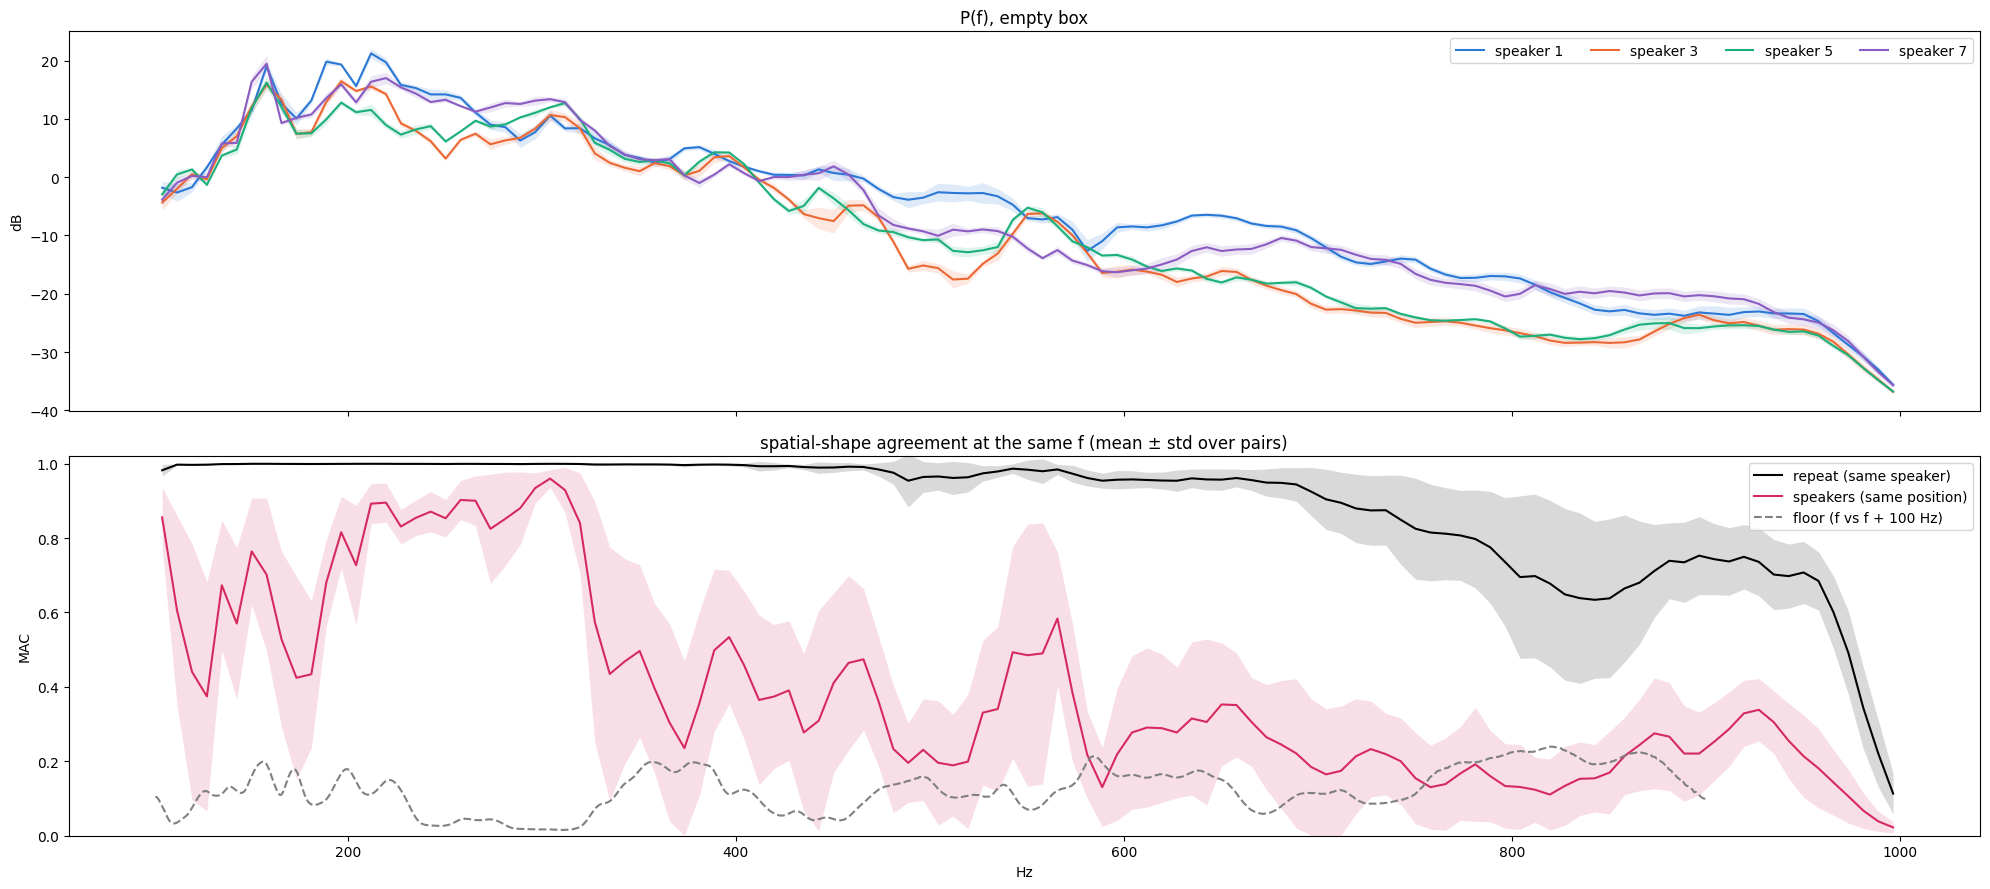

In [2]:
spk = np.array([mac(x[a], x[b]) for _, g in df[E].groupby(["layout", "pos"]) for k, a in enumerate(g.index) for b in g.index[k + 1:]])
ra = np.concatenate(list(rep.values()))
fig, axs = plt.subplots(2, 1, figsize=(20, 9), sharex=True)
for s in SPK:
    m, sd = band(P[E & (df.spk == s)]).mean(0), band(P[E & (df.spk == s)]).std(0)
    axs[0].fill_between(fb, m - sd, m + sd, color=SC[s], alpha=.15, lw=0); axs[0].plot(fb, m, c=SC[s], label=f"speaker {s}")
for v, c, l in ((ra, "k", "repeat (same speaker)"), (spk, "#d62a5f", "speakers (same position)")):
    m, sd = band(v).mean(0), band(v).std(0)
    axs[1].fill_between(fb, m - sd, m + sd, color=c, alpha=.15, lw=0); axs[1].plot(fb, m, c=c, label=l)
axs[1].plot(f[:-130], uniform_filter1d(floor, 10), c="gray", ls="--", label="floor (f vs f + 100 Hz)")
axs[0].set(ylabel="dB", title="P(f), empty box"); axs[0].legend(ncol=4)
axs[1].set(xlabel="Hz", ylabel="MAC", ylim=(0, 1.02), title="spatial-shape agreement at the same f (mean ± std over pairs)"); axs[1].legend()
plt.tight_layout()
w = (f > 180) & (f < 320)
summary["MAC repeat, 100-700 Hz"] = pm(ra[:, :780].mean(1))
summary["MAC speakers, 100-700 Hz"] = pm(spk[:, :780].mean(1))
summary["MAC speakers, 180-320 Hz"] = pm(spk[:, w].mean(1))
summary["MAC floor, 100-700 Hz"] = f"{floor[:780].mean():.2f}"
show("MAC repeat, 100-700 Hz", "MAC speakers, 100-700 Hz", "MAC speakers, 180-320 Hz", "MAC floor, 100-700 Hz")

In [3]:
h1 = E & df.layout.isin(HALF); h2 = E & ~df.layout.isin(HALF)
out = {}
for k in (8, 16, 32):
    V = {s: top(df.index[h1 & (df.spk == s)], k) for s in SPK}
    out[k] = pd.DataFrame([[capture(V[a], df.index[h2 & (df.spk == b)]) for b in SPK] for a in SPK], index=[f"V of spk {a}" for a in SPK], columns=[f"spk {b}" for b in SPK])
    M = out[k].values
    summary[f"capture own, k={k}"], summary[f"capture other, k={k}"] = pm(np.diag(M), ".3f"), pm(M[~np.eye(4, dtype=bool)], ".3f")
pd.concat(out, names=["k"]).round(3)

spk 1  spk 3  spk 5  spk 7
k                                        
8  V of spk 1  0.853  0.663  0.640  0.657
   V of spk 3  0.688  0.812  0.679  0.693
   V of spk 5  0.709  0.692  0.822  0.739
   V of spk 7  0.673  0.682  0.692  0.869
16 V of spk 1  0.952  0.850  0.836  0.894
   V of spk 3  0.882  0.899  0.862  0.897
   V of spk 5  0.898  0.855  0.912  0.911
   V of spk 7  0.874  0.847  0.867  0.957
32 V of spk 1  0.965  0.905  0.917  0.957
   V of spk 3  0.944  0.915  0.917  0.954
   V of spk 5  0.947  0.905  0.928  0.957
   V of spk 7  0.955  0.903  0.919  0.968

**Reading:**
- **Shapes at the same `f` agree between speakers only at ~180-320 Hz** (MAC 0.8-0.95), the band of the strongest shared resonances. Elsewhere they fall to 0.2-0.5, not far above the floor, while repeats of one speaker stay ≥ 0.95 up to ~700 Hz. So at most frequencies two speakers make the wall move in **different** shapes, and that is not noise.
- **The pattern set is shared, the ranking is not** (table, read down each column). At k = 8 a speaker's own patterns hold 0.81-0.87 of its held-out shapes, another speaker's only 0.64-0.74. By k = 32 the gap nearly closes (0.92-0.97 vs 0.90-0.96).

**Answer: same patterns, different mix.** All four speakers live in nearly the same ~32 spatial patterns, but each drives a different subset hardest, so the wall's shape at a given frequency depends on the speaker. Stacking speakers is safe for pattern *sets* (subspaces), not for shapes at one frequency, so **every comparison below is within one speaker**, averaged over speakers.

# 3 Does the Wall's Shape Change With Position, or Is It Drift?

**Question.** Before looking at individual modes: when the cube moves, does the wall's spatial shape change at all? And is the change due to where the cube is, or to the time between the two captures (drift)?

**Definitions.**
```
pair MAC  = mean_{100-700 Hz} MAC(x_a(f), x_b(f)), a and b = two cube captures, same speaker   # spatial shape compared at every f, then averaged
D_pos     = distance between the two cube positions / box size
Δt        = minutes between the two captures
fit       = least squares  pair MAC = c0 + c1 · D_pos + c2 · Δt(hours)
```
100-700 Hz is where repeats are ≥ 0.96 (§2). Between resonances the wall shows a blend of modes, so this compares the deflection shape at every frequency, not only at peaks (that is §6).

,value
"pair MAC, repeat ceiling",0.984
"pair MAC, close (D_pos < 0.05)",0.878 ± 0.018
"pair MAC, far (D_pos > 0.4)",0.721 ± 0.017
fit: MAC per box length moved,-0.181
fit: MAC per hour,-0.0018


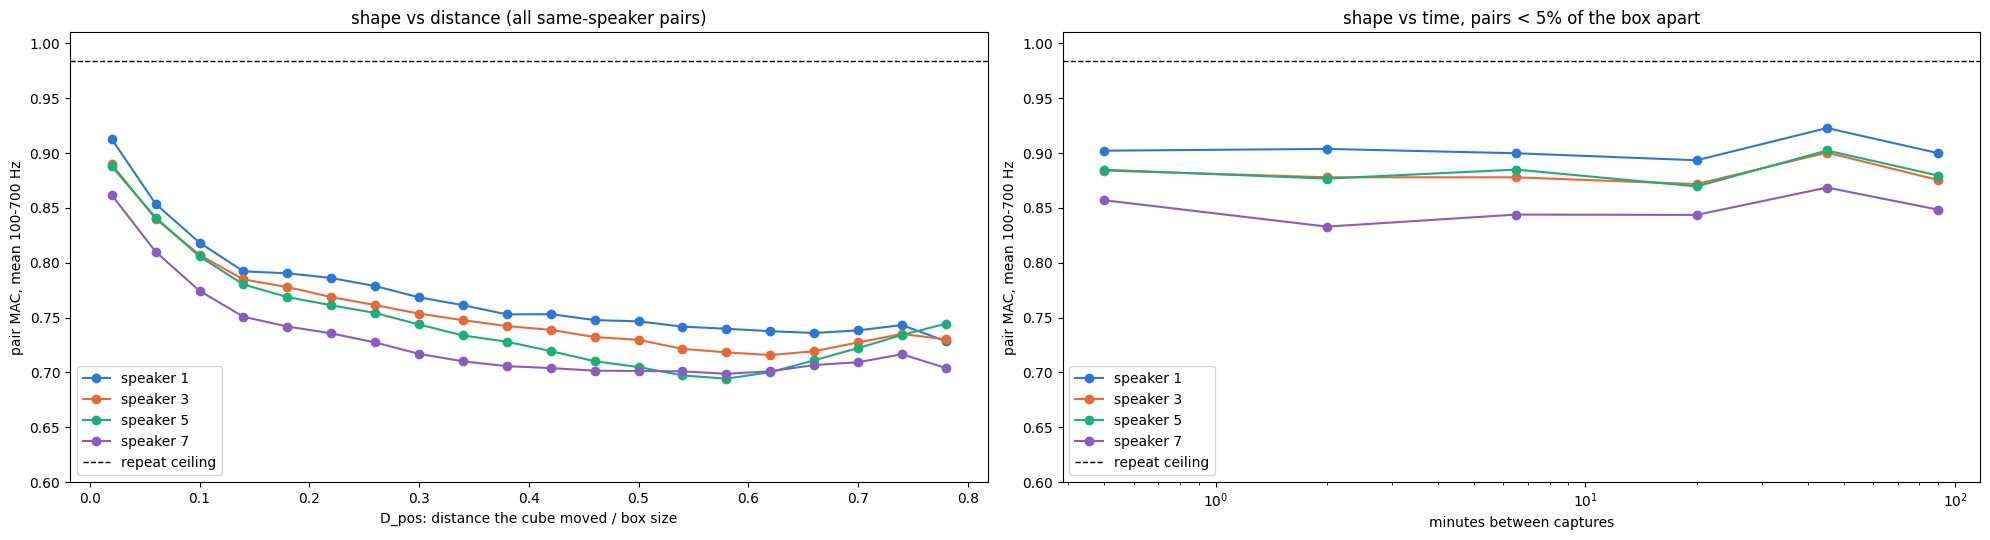

In [4]:
B = slice(0, 780)                                                              # 100-700 Hz, 78 bands of 10 bins
pr = []
for s in SPK:
    g = df[Cb & (df.spk == s)]
    xi = x[g.index][:, B].transpose(1, 0, 2)                                   # (F, n, 200)
    M = np.abs(xi @ xi.conj().transpose(0, 2, 1)) ** 2                          # (F, n, n) MAC per f
    i, j = np.triu_indices(len(g), 1)
    pr.append(pd.DataFrame(dict(spk=s, mac=M.mean(0)[i, j], dpos=np.hypot(g.row.values[i] - g.row.values[j], g.col.values[i] - g.col.values[j]) / 1151,
                                dt=np.abs(g.t.values[i] - g.t.values[j]))))
    if s == 1: Mf, d1 = M[:, i, j].T.reshape(-1, 78, 10).mean(2), pr[-1].dpos.values   # per-band MAC, speaker 1
pr = pd.concat(pr, ignore_index=True)
ceil = np.mean([rep[s][:, B].mean() for s in SPK])

fig, axs = plt.subplots(1, 2, figsize=(20, 5.5))
for ax, key, sub, bins in ((axs[0], "dpos", pr, np.arange(0, .85, .04)), (axs[1], "dt", pr[pr.dpos < .05], [0, 1, 3, 10, 30, 60, 120, 240])):
    for s in SPK:
        q = sub[sub.spk == s]; st = q.mac.groupby(pd.cut(q[key], bins), observed=True).mean()
        ax.plot([iv.mid for iv in st.index], st.values, "o-", c=SC[s], label=f"speaker {s}")
    ax.axhline(ceil, c="k", ls="--", lw=1, label="repeat ceiling")
    ax.set(ylabel="pair MAC, mean 100-700 Hz", ylim=(.6, 1.01)); ax.legend()
axs[0].set(xlabel="D_pos: distance the cube moved / box size", title="shape vs distance (all same-speaker pairs)")
axs[1].set(xlabel="minutes between captures", xscale="log", title="shape vs time, pairs < 5% of the box apart")
plt.tight_layout()
c0, c1, c2 = np.linalg.lstsq(np.c_[np.ones(len(pr)), pr.dpos, pr.dt / 60], pr.mac, rcond=None)[0]
per = lambda w: [pr.mac[w & (pr.spk == s)].mean() for s in SPK]                # mean over pairs, then mean ± std over speakers
summary["pair MAC, repeat ceiling"] = f"{ceil:.3f}"
summary["pair MAC, close (D_pos < 0.05)"] = pm(per(pr.dpos < .05), ".3f")
summary["pair MAC, far (D_pos > 0.4)"] = pm(per(pr.dpos > .4), ".3f")
summary["fit: MAC per box length moved"] = f"{c1:+.3f}"
summary["fit: MAC per hour"] = f"{c2:+.4f}"
show("pair MAC, repeat ceiling", "pair MAC, close (D_pos < 0.05)", "pair MAC, far (D_pos > 0.4)", "fit: MAC per box length moved", "fit: MAC per hour")

Supporting: which frequencies change. Speaker 1, MAC per 7.7 Hz band for close and far pairs, with the repeat ceiling (dotted: speaker-1 empty peaks).

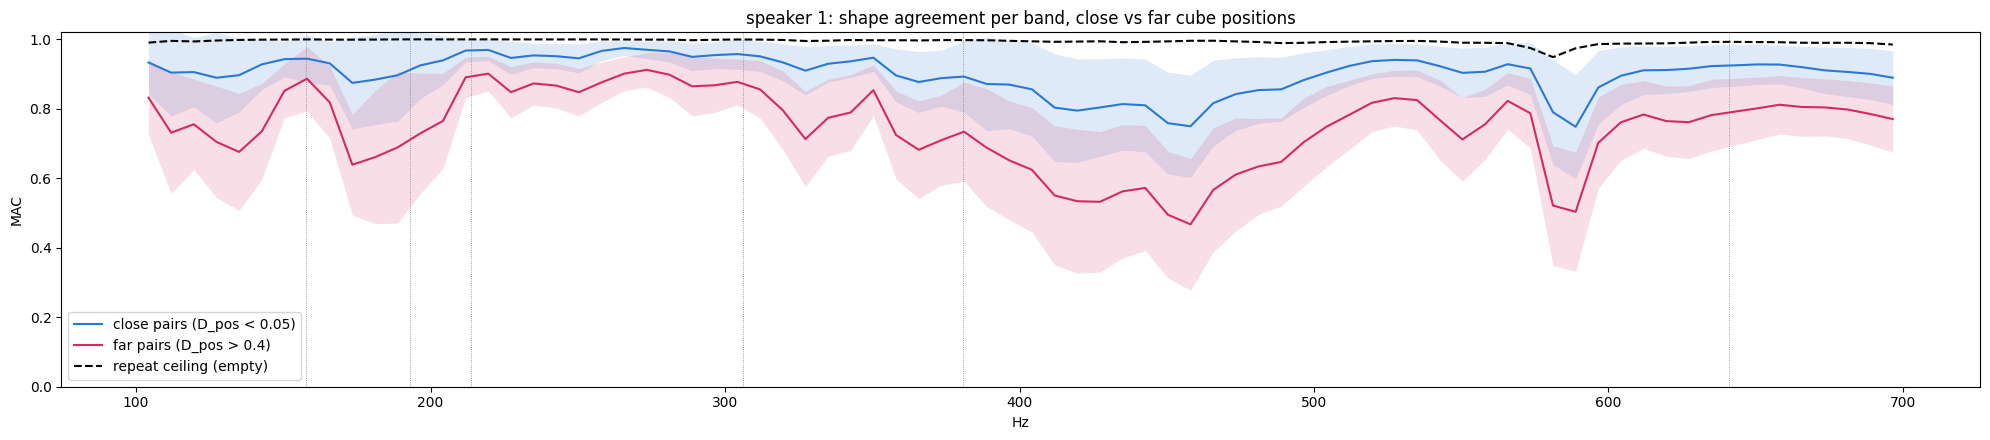

In [5]:
fbB = fb[:78]
fig, ax = plt.subplots(figsize=(20, 4.5))
for w, c, l in ((d1 < .05, "#2a78d6", "close pairs (D_pos < 0.05)"), (d1 > .4, "#d62a5f", "far pairs (D_pos > 0.4)")):
    m, sd = Mf[w].mean(0), Mf[w].std(0)
    ax.fill_between(fbB, m - sd, m + sd, color=c, alpha=.15, lw=0); ax.plot(fbB, m, c=c, label=l)
ax.plot(fbB, band(rep[1]).mean(0)[:78], c="k", ls="--", label="repeat ceiling (empty)")
for p0 in f[find_peaks(uniform_filter1d(P[E & (df.spk == 1)].mean(0), 7), prominence=3)[0]]:
    if p0 < 700: ax.axvline(p0, c="gray", lw=.6, ls=":")
ax.set(xlabel="Hz", ylabel="MAC", ylim=(0, 1.02), title="speaker 1: shape agreement per band, close vs far cube positions"); ax.legend()
plt.tight_layout()

**Reading:**
- **Shapes change with position.** Pair MAC falls fast from ~0.89 (cube moved < 4% of the box) to ~0.78 at 15% of the box, then slowly to ~0.70-0.74 at half the box, and is flat beyond. The repeat ceiling is 0.98, so even the closest pairs differ a little.
- **It is position, not time.** Close pairs stay at 0.84-0.92 whether they were recorded 30 s or 90 min apart. The joint fit gives about −0.18 MAC per box length moved and ≈ 0 per hour.
- Speakers rank the same at every distance (1 highest, 7 lowest), so the trend is not one speaker's.
- By frequency (speaker 1): the least change is at the strong shared resonances (~155 Hz, 220-310 Hz, far pairs 0.85-0.9), the most between resonances (400-480 Hz: 0.47-0.55 vs ~0.8 for close pairs), where the wall shows a blend of overlapping modes.

**Answer: yes, and it is position.** The wall's spatial shape changes with where the cube sits, more the farther it moves, saturating after ~15% of the box; time between captures explains nothing.

# 4 Empty Box vs Cube: New Modes, or the Same Modes Reweighted?

**Question.** Does putting the cube in the box (anywhere) create spatial patterns or resonance peaks the empty box does not have? Or does it only change how much of each existing mode the wall shows?

**Definitions.**
```
peak       = find_peaks(P(f) smoothed over 7 bins, prominence ≥ 3 dB), per capture
mode       = a 15 Hz cluster of peaks pooled over all cube captures (histogram in 5 Hz bins)
has mode   = the capture has a peak within ±8 Hz of the cluster centre
occurrence = fraction of captures (one speaker, cube or empty) that have the mode
new patterns test: capture(V_k(empty sessions 1/3/5), cube captures) vs capture(same V, empty sessions 2/4)
```

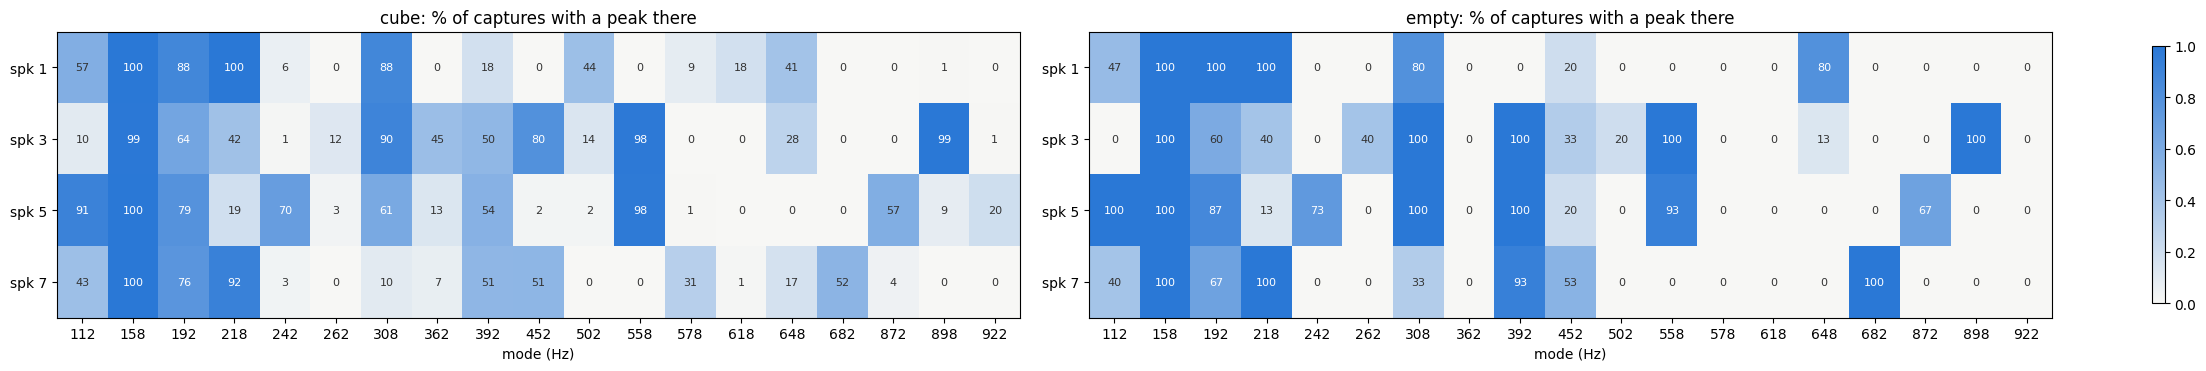

In [6]:
W = 8
Ps = uniform_filter1d(P, 7, axis=1)
pks = [f[find_peaks(p, prominence=3)[0]] for p in Ps]
h = np.convolve(np.histogram(np.concatenate([p for p, c in zip(pks, Cb) if c]), np.arange(100, 1001, 5))[0], np.ones(3), "same")
MODES = np.arange(102.5, 1000, 5)[find_peaks(h, distance=3)[0]]
has = np.array([[len(p) > 0 and np.abs(p - c).min() < W for c in MODES] for p in pks])         # (captures, modes)
occ = {o: np.array([has[(df.obj == o) & (df.spk == s)].mean(0) for s in SPK]) for o in ("cube", "empty")}
show_m = np.maximum(occ["cube"], occ["empty"]).max(0) >= .1
fig, axs = plt.subplots(1, 2, figsize=(22, 3.6), layout="constrained")
for ax, (o, v) in zip(axs, occ.items()):
    im = ax.imshow(v[:, show_m], cmap=LinearSegmentedColormap.from_list("seq", ["#f7f7f5", "#2a78d6"]), vmin=0, vmax=1, aspect="auto")
    for (r, c), val in np.ndenumerate(v[:, show_m]): ax.text(c, r, f"{val:.0%}"[:-1], ha="center", va="center", fontsize=8, color="white" if val > .6 else "#333")
    ax.set(xticks=range(show_m.sum()), xticklabels=[f"{c:.0f}" for c in MODES[show_m]], yticks=range(4), yticklabels=[f"spk {s}" for s in SPK], title=f"{o}: % of captures with a peak there", xlabel="mode (Hz)")
fig.colorbar(im, ax=axs, shrink=.9)

In [7]:
res = []
for k in (8, 16, 32):
    for s in SPK:
        V = top(df.index[h1 & (df.spk == s)], k)
        res.append(dict(k=k, spk=s, empty_heldout=capture(V, df.index[h2 & (df.spk == s)]), cube=capture(V, df.index[Cb & (df.spk == s)])))
res = pd.DataFrame(res)
for k in (8, 32):
    summary[f"capture by empty V, empty held-out, k={k}"] = pm(res[res.k == k].empty_heldout, ".3f")
    summary[f"capture by empty V, cube, k={k}"] = pm(res[res.k == k].cube, ".3f")
summary["modes in ≥ 90% of every speaker's captures"] = ", ".join(f"{c:.0f} Hz" for c in MODES[np.minimum(occ["cube"], occ["empty"]).min(0) >= .9])
res.groupby("k")[["empty_heldout", "cube"]].agg(lambda v: pm(v, ".3f"))

,empty_heldout,cube
k,,
8,0.839 ± 0.023,0.792 ± 0.024
16,0.930 ± 0.025,0.912 ± 0.022
32,0.944 ± 0.023,0.939 ± 0.022


**Reading:**
- **No new spatial patterns.** The empty box's top 8 patterns hold a bit less of the cube shapes than of held-out empty shapes (0.79 vs 0.84), at k = 16 0.91 vs 0.93, and at k = 32 they are equal (0.939 vs 0.944). The cube moves ~5% of the shape energy from the strongest empty patterns into weaker ones, within the same ~32 (matches nb99: cube ≈ empty eff_rank in plastic).
- **Peaks do appear and fade.** Appear: 362 Hz (speaker 3, 0 → 45%), 502 Hz (speaker 1, 0 → 44%), 578 Hz (speaker 7, 0 → 31%). Fade: 393 Hz (speaker 3, 100 → 50%), 648 Hz (speaker 1, 80 → 41%), 308 Hz (speaker 7, 33 → 10%). With no new patterns, these are not new modes: the cube changes which overlapping mode stands out enough to make a peak.
- **Only ~158 Hz is universal** (≥ 98% of every speaker's captures, empty or cube). Every other mode is speaker-specific: ~218 Hz is 92-100% for speakers 1/7 but 19-42% for 3/5; ~558 Hz is 98% for speakers 3/5 and absent for 1/7; ~898 Hz is speaker 3 only. How common a mode is, is mostly how many speakers drive it (§2).

**Answer: the same modes, reweighted.** The cube creates no new spatial patterns; it shifts weight between existing ones, enough to make some peaks appear or disappear.

From here on, a **track** is one (mode, speaker) pair found in ≥ 50% of both the cube and the empty captures of that speaker. A mode is only ever compared with itself, from the same speaker. For each capture in a track:
```
f_peak   = the capture's own peak nearest the mode (within ±8 Hz); no peak → left out
level    = smoothed P at f_peak (dB)
z        = x(f_peak): the capture's mode shape at its own peak (so a frequency shift is not counted as a shape change)
v_empty  = top eigenvector of the empty captures' shapes at the empty mean peak (±1 bin): the empty-box mode shape
shape    = 1 − MAC(z, v_empty)
```

In [8]:
tracks = [(c, s) for c in MODES for k, s in enumerate(SPK) if occ["cube"][k, MODES.tolist().index(c)] >= .5 and occ["empty"][k, MODES.tolist().index(c)] >= .5]
rows, T = [], []
for c, s in tracks:
    idx = np.flatnonzero(df.spk == s)
    fp = np.array([(lambda p: p[np.abs(p - c).argmin()] if len(p) else np.nan)(pks[i][np.abs(pks[i] - c) < W]) for i in idx])
    idx, fp = idx[~np.isnan(fp)], fp[~np.isnan(fp)]
    k = np.abs(f[:, None] - fp).argmin(0)                                    # each capture's own peak bin
    e = (df.obj.values[idx] == "empty")
    ke = np.abs(f - fp[e].mean()).argmin()
    v = np.linalg.eigh(np.einsum("nfa,nfb->ab", x[idx[e], ke - 1:ke + 2].conj(), x[idx[e], ke - 1:ke + 2]))[1][:, -1]   # empty-box shape at the empty peak
    z = x[idx, k]                                                            # each capture's shape at its own peak
    rows.append(pd.DataFrame(dict(mode=c, spk=s, i=idx, obj=df.obj.values[idx], pos=df.pos.values[idx], row=df.row.values[idx], col=df.col.values[idx],
                                  fpk=fp, level=Ps[idx, k], shape=1 - np.abs(z @ v) ** 2, mpc=np.abs((z * z).sum(-1)) ** 2)))
    lin = 10 ** (Ps[idx[e]].mean(0) / 10)                                    # empty-box spectrum of this speaker, for damping and crowding
    kp = ke - 3 + lin[ke - 3:ke + 4].argmax()
    nb = f[find_peaks(10 * np.log10(lin), prominence=1)[0]]
    T.append(dict(mode=c, spk=s, f_e=fp[e].mean(), level_e=Ps[idx[e], ke].mean(), eta=peak_widths(lin, [kp], rel_height=.5)[0][0] * (f[1] - f[0]) / f[kp],
                  gap=np.abs(nb[np.abs(nb - f[kp]) > 3] - f[kp]).min()))
t = pd.concat(rows, ignore_index=True)
T = pd.DataFrame(T).set_index(["mode", "spk"])
TN = [f"{c:.0f}·s{s}" for c, s in T.index]
summary["tracks (mode, speaker)"] = str(len(T))
print(len(T), "tracks:", ", ".join(TN))

24 tracks: 112·s5, 158·s1, 158·s3, 158·s5, 158·s7, 192·s1, 192·s3, 192·s5, 192·s7, 218·s1, 218·s7, 242·s5, 308·s1, 308·s3, 308·s5, 392·s3, 392·s5, 392·s7, 452·s7, 558·s3, 558·s5, 682·s7, 872·s5, 898·s3


/tmp/ipykernel_3384739/3637192588.py:17: PeakPropertyWarning: some peaks have a prominence of 0
  T.append(dict(mode=c, spk=s, f_e=fp[e].mean(), level_e=Ps[idx[e], ke].mean(), eta=peak_widths(lin, [kp], rel_height=.5)[0][0] * (f[1] - f[0]) / f[kp],
/tmp/ipykernel_3384739/3637192588.py:17: PeakPropertyWarning: some peaks have a width of 0
  T.append(dict(mode=c, spk=s, f_e=fp[e].mean(), level_e=Ps[idx[e], ke].mean(), eta=peak_widths(lin, [kp], rel_height=.5)[0][0] * (f[1] - f[0]) / f[kp],


# 5 Q1: Does a Mode's Frequency and Amplitude Change With Position?

**Question.** For the same mode and speaker: how much does the peak frequency move as the cube moves? Does it move more when the two positions are farther apart? And does the amplitude change too, or only the frequency?

**Definitions** (per track):
```
spread / noise   = std of f_peak (or level) over cube positions / std over the 15 empty captures   # 1 = indistinguishable from noise
shift vs empty   = mean f_peak(cube) − mean f_peak(empty)          (level: same, in dB)
pairwise         = |Δf_peak| (or |Δlevel|) between two cube positions, binned by D_pos, ÷ the mean over empty pairs
```
The empty std is floored at 0.4 Hz (half an FFT bin): some empty peaks never move.

,112·s5,158·s1,158·s3,158·s5,158·s7,192·s1,192·s3,192·s5,192·s7,218·s1,...,308·s5,392·s3,392·s5,392·s7,452·s7,558·s3,558·s5,682·s7,872·s5,898·s3
freq std cube (Hz),1.62,0.49,1.86,0.97,0.76,1.67,2.85,1.61,0.80,1.43,...,4.02,3.54,4.82,2.44,1.66,3.01,4.41,2.69,1.72,1.37
freq std empty (Hz),0.32,0.60,2.68,1.00,0.96,0.00,0.46,0.37,0.67,1.42,...,3.03,2.86,1.35,0.00,0.00,2.68,1.84,1.33,1.70,1.16
level std cube (dB),0.72,1.27,1.00,1.19,1.32,1.27,0.86,1.07,1.17,1.12,...,1.07,1.50,1.47,1.43,1.38,1.15,1.25,1.10,0.91,0.97
level std empty (dB),0.62,0.71,0.88,1.11,0.94,0.41,0.32,0.51,0.56,0.72,...,0.48,0.73,0.28,0.48,1.01,0.60,0.44,0.59,0.88,0.78
freq / noise,4.06,0.82,0.69,0.97,0.80,4.18,6.17,4.04,1.19,1.01,...,1.33,1.24,3.58,6.11,4.16,1.12,2.40,2.02,1.01,1.19
level / noise,1.16,1.79,1.14,1.08,1.40,3.13,2.70,2.10,2.10,1.56,...,2.22,2.04,5.28,2.96,1.37,1.94,2.86,1.86,1.03,1.24
freq std / f0 (%),1.39,0.31,1.18,0.62,0.49,0.86,1.45,0.82,0.41,0.67,...,1.29,0.90,1.22,0.62,0.37,0.54,0.80,0.39,0.20,0.15
freq shift vs empty (Hz),0.18,0.04,0.40,1.30,0.74,0.10,0.24,0.33,0.90,-0.85,...,-2.36,2.48,-1.15,-1.40,-0.41,4.45,7.81,0.74,0.83,0.69
level change vs empty (dB),-0.42,-0.62,0.03,0.04,-0.24,-1.68,-0.23,0.39,1.15,-0.87,...,-0.76,-1.94,-1.15,1.00,-1.13,0.04,0.17,-0.81,-0.66,-0.66


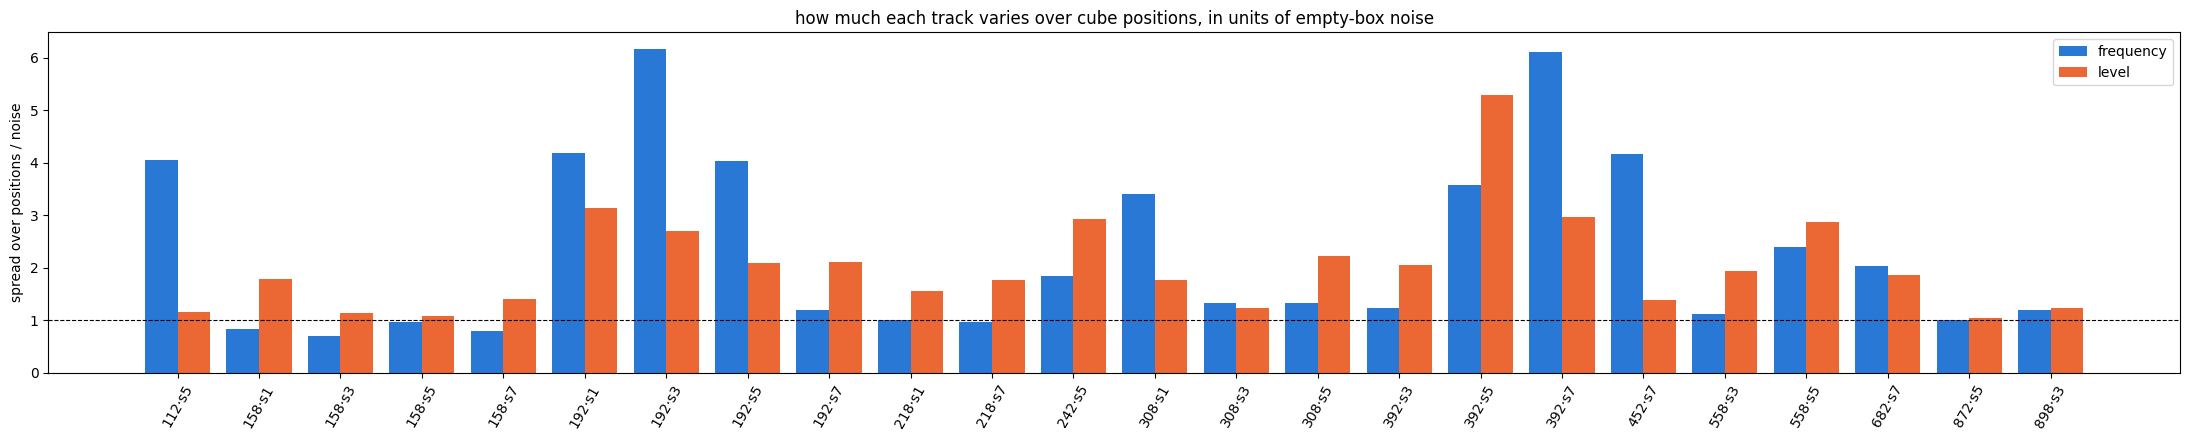

In [9]:
g = t.groupby(["mode", "spk", "obj"])
Z = pd.DataFrame({"freq std cube (Hz)": g["fpk"].std().unstack()["cube"], "freq std empty (Hz)": g["fpk"].std().unstack()["empty"],
                  "level std cube (dB)": g["level"].std().unstack()["cube"], "level std empty (dB)": g["level"].std().unstack()["empty"]})
Z["freq / noise"] = Z.iloc[:, 0] / Z.iloc[:, 1].clip(lower=.4)
Z["level / noise"] = Z.iloc[:, 2] / Z.iloc[:, 3]
Z["freq std / f0 (%)"] = 100 * Z.iloc[:, 0] / T.f_e
Z["freq shift vs empty (Hz)"] = g["fpk"].mean().unstack()["cube"] - g["fpk"].mean().unstack()["empty"]
Z["level change vs empty (dB)"] = g["level"].mean().unstack()["cube"] - g["level"].mean().unstack()["empty"]
fig, ax = plt.subplots(figsize=(22, 4.5))
ax.bar(np.arange(len(Z)) - .2, Z["freq / noise"], .4, color="#2a78d6", label="frequency")
ax.bar(np.arange(len(Z)) + .2, Z["level / noise"], .4, color="#eb6834", label="level")
ax.axhline(1, c="k", lw=.8, ls="--")
ax.set(xticks=range(len(Z)), xticklabels=TN, ylabel="spread over positions / noise", title="how much each track varies over cube positions, in units of empty-box noise"); ax.legend()
plt.setp(ax.get_xticklabels(), rotation=60); plt.tight_layout()
for k in ("freq std cube (Hz)", "freq std / f0 (%)", "freq / noise", "level std cube (dB)", "level / noise"): summary[f"{k}, over tracks"] = pm(Z[k])
Z.round(2).T.set_axis(TN, axis=1)

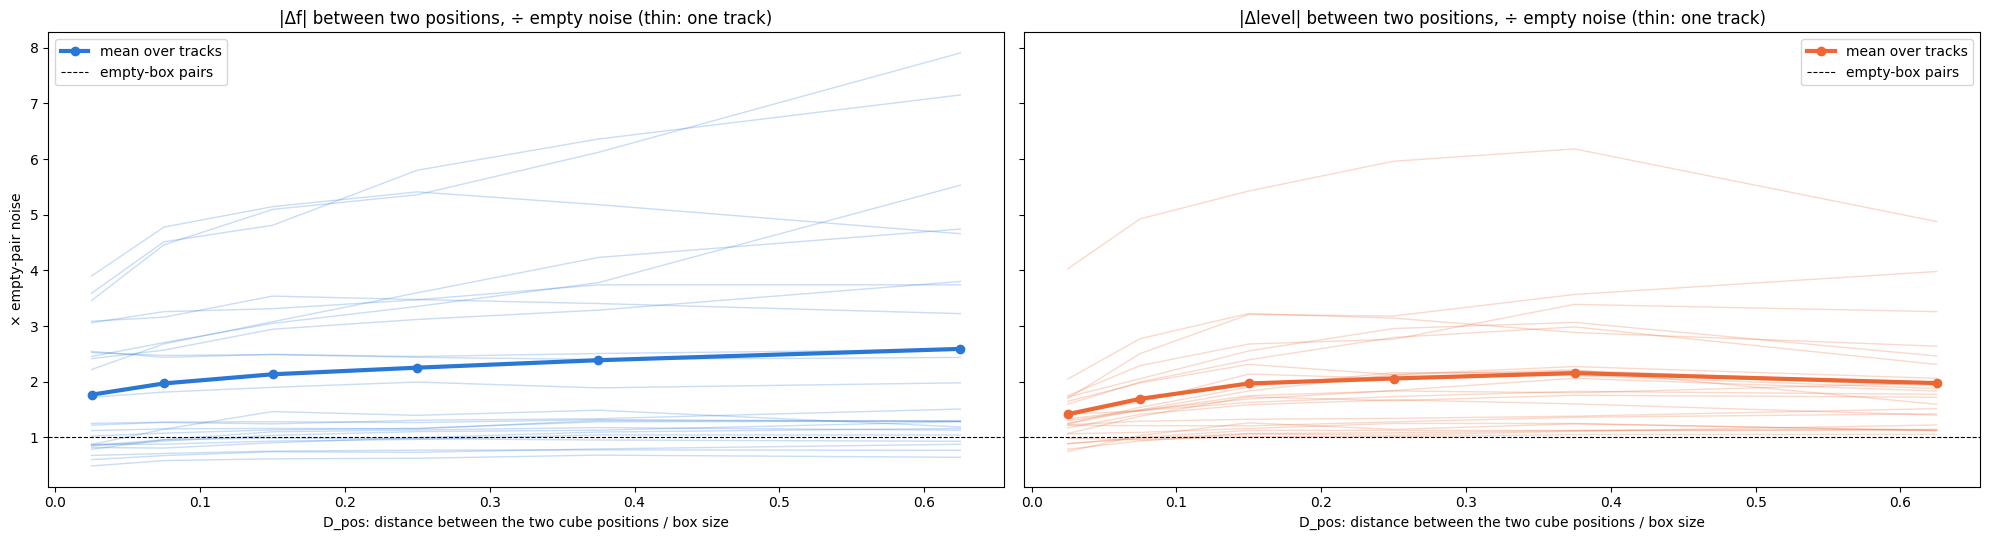

In [10]:
bins = [0, .05, .1, .2, .3, .45, .8]
mid = [(a + b) / 2 for a, b in zip(bins[:-1], bins[1:])]
PR = []
for (c, s), g in t.groupby(["mode", "spk"]):
    cu, em = g[g.obj == "cube"], g[g.obj == "empty"]
    i, j = np.triu_indices(len(cu), 1); ie, je = np.triu_indices(len(em), 1)
    za, zb = x[cu.i.values[i], np.abs(f[:, None] - cu.fpk.values[i]).argmin(0)], x[cu.i.values[j], np.abs(f[:, None] - cu.fpk.values[j]).argmin(0)]
    zea, zeb = x[em.i.values[ie], np.abs(f[:, None] - em.fpk.values[ie]).argmin(0)], x[em.i.values[je], np.abs(f[:, None] - em.fpk.values[je]).argmin(0)]
    d = pd.DataFrame(dict(D=np.hypot(cu.row.values[i] - cu.row.values[j], cu.col.values[i] - cu.col.values[j]) / 1151,
                          freq=np.abs(cu.fpk.values[i] - cu.fpk.values[j]), level=np.abs(cu["level"].values[i] - cu["level"].values[j]), shape=1 - mac(za, zb)))
    noise = dict(freq=max(np.abs(em.fpk.values[ie] - em.fpk.values[je]).mean(), .4), level=np.abs(em["level"].values[ie] - em["level"].values[je]).mean(), shape=(1 - mac(zea, zeb)).mean())
    b = d.groupby(pd.cut(d.D, bins), observed=False)[["freq", "level", "shape"]].mean()
    PR.append(dict(mode=c, spk=s, **{f"{k} close": b[k].iloc[0] for k in noise}, **{f"{k} far": b[k].iloc[-1] for k in noise}, **{f"{k} noise": noise[k] for k in noise}, curve=b))
PR = pd.DataFrame(PR).set_index(["mode", "spk"])

fig, axs = plt.subplots(1, 2, figsize=(20, 5.5), sharey=True)
for ax, key, c in ((axs[0], "freq", "#2a78d6"), (axs[1], "level", "#eb6834")):
    Y = np.stack([cv[key].values / PR.loc[ix, f"{key} noise"] for ix, cv in PR.curve.items()])
    for y in Y: ax.plot(mid, y, c=c, alpha=.25, lw=1)
    ax.plot(mid, np.nanmean(Y, 0), "o-", c=c, lw=3, label="mean over tracks")
    ax.axhline(1, c="k", lw=.8, ls="--", label="empty-box pairs")
    ax.set(xlabel="D_pos: distance between the two cube positions / box size", title=f"|Δ{'f' if key == 'freq' else 'level'}| between two positions, ÷ empty noise (thin: one track)"); ax.legend()
    summary[f"|Δ{key}| / noise, close pairs (D_pos < 0.05)"], summary[f"|Δ{key}| / noise, far pairs (D_pos > 0.45)"] = pm(Y[:, 0]), pm(Y[:, -1])
axs[0].set_ylabel("× empty-pair noise")
plt.tight_layout()

**Reading:**
- **Frequency moves by 0.5-4.8 Hz (std over positions), 0.15-1.45% of the mode's frequency.** ~158 Hz does not move beyond noise for any speaker (ratio 0.7-1.0). Clearly above noise (≥ 3×): ~113, ~193 (speakers 1/3/5), ~308 (speaker 1), ~393 (speakers 5/7) and ~452 Hz. The rest are 1-2.4×.
- **It moves more with distance, on average.** `|Δf|` rises from 1.75× noise (positions < 5% of the box apart) to 2.6× (more than half a box). The tracks split: about a third rise steeply (to 5-8×: ~193, ~393, ~452 Hz), the rest stay flat near 1 (~158 Hz among them).
- **The amplitude changes too.** Every track's level varies more over positions than over repeats (1.03-5.3×; largest ~393 Hz speaker 5 and ~193 Hz speaker 1), and `|Δlevel|` rises from 1.4× noise for close pairs to ~2.1× by 0.15-0.4 of the box, then flattens.
- **No common direction vs the empty box.** Mean shifts are within ±1.5 Hz and −1.9 to +1.2 dB for most tracks: the cube makes a mode louder at some positions and quieter at others. The outlier is **~558 Hz, +4.5 / +7.8 Hz** (speakers 3 / 5). Added mass can only lower a frequency, so a rise means stiffening or a different peak taking over (the empty and cube captures were also recorded at different times).

**Answer: both change, frequency only a little.** Peaks move by up to ~1.5% of f, for about a third of the modes clearly more than noise and more with distance; ~158 Hz does not move. The amplitude changes for every mode (1-5× noise) and grows with distance. Frequency and level are separate: ~158 Hz keeps its frequency, but its level still varies 1.1-1.8× noise.

# 6 Q2: At the Same Mode, Does the Mode Shape Differ Between Positions?

**Question.** Take one mode (one track). At each cube position, read the wall's spatial pattern at that position's own peak. Do two positions give the same mode shape on the lasers? Does the difference grow with the distance between them?

**Definitions** (per track):
```
1 − MAC(z_a, z_b)  = mode-shape difference between two cube captures, each at its own peak   # 0 = identical pattern on the 100 lasers
noise              = mean 1 − MAC over empty-capture pairs of the same track
shape vs empty     = 1 − MAC(z, v_empty) (§4), mean over cube captures (and over empty captures, as its noise)
```
Shown in absolute units: the empty noise is 0.004-0.04 for most tracks, so ratios explode. ~898 Hz is left out of the plot: at −24 dB even empty repeats disagree (0.14).

,112·s5,158·s1,158·s3,158·s5,158·s7,192·s1,192·s3,192·s5,192·s7,218·s1,...,308·s5,392·s3,392·s5,392·s7,452·s7,558·s3,558·s5,682·s7,872·s5,898·s3
shape noise,0.012,0.021,0.074,0.006,0.004,0.013,0.007,0.011,0.015,0.004,...,0.038,0.012,0.010,0.025,0.033,0.026,0.024,0.041,0.246,0.265
shape close,0.018,0.053,0.049,0.017,0.013,0.053,0.038,0.042,0.050,0.027,...,0.041,0.083,0.075,0.068,0.073,0.053,0.044,0.110,0.302,0.316
shape far,0.029,0.116,0.078,0.036,0.034,0.158,0.091,0.105,0.173,0.081,...,0.100,0.310,0.247,0.235,0.155,0.112,0.122,0.193,0.327,0.313
vs empty: cube,0.020,0.054,0.052,0.031,0.024,0.098,0.062,0.071,0.100,0.047,...,0.073,0.162,0.155,0.161,0.106,0.108,0.088,0.121,0.188,0.191
vs empty: empty,0.006,0.010,0.041,0.003,0.002,0.006,0.003,0.005,0.007,0.002,...,0.019,0.006,0.005,0.012,0.015,0.013,0.011,0.020,0.132,0.143


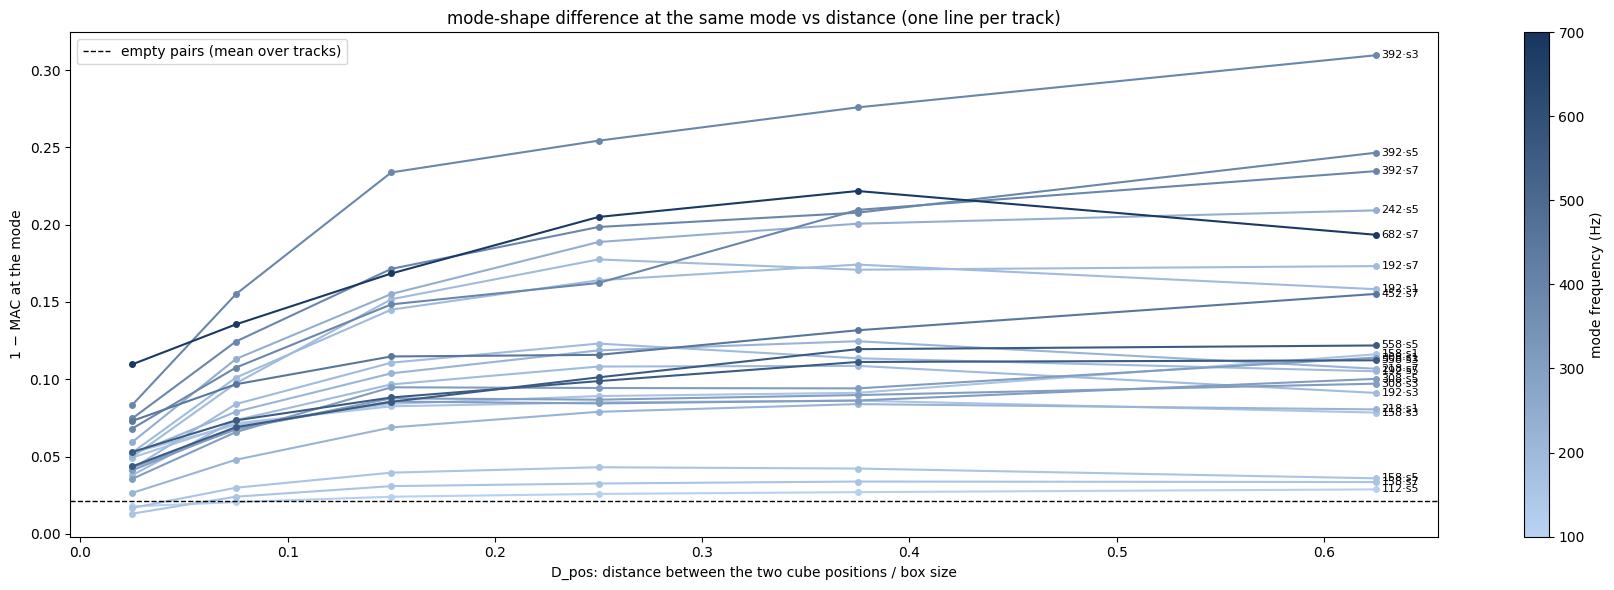

In [11]:
fig, ax = plt.subplots(figsize=(18, 6))
cm = plt.cm.ScalarMappable(plt.Normalize(100, 700), LinearSegmentedColormap.from_list("seq", ["#b9d3f2", "#16365f"]))
for (c, s), r in PR.iterrows():
    if c > 800: continue
    ax.plot(mid, r.curve["shape"], "o-", c=cm.to_rgba(c), lw=1.5, ms=4)
    ax.annotate(f"{c:.0f}·s{s}", (mid[-1], r.curve["shape"].iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=8, va="center")
lo = PR.index.get_level_values(0) < 800
ax.axhline(PR[lo]["shape noise"].mean(), c="k", ls="--", lw=1, label="empty pairs (mean over tracks)")
fig.colorbar(cm, ax=ax, label="mode frequency (Hz)")
ax.set(xlabel="D_pos: distance between the two cube positions / box size", ylabel="1 − MAC at the mode", title="mode-shape difference at the same mode vs distance (one line per track)"); ax.legend()
plt.tight_layout()
g = t.groupby(["mode", "spk", "obj"])["shape"].mean().unstack()
for k in ("shape noise", "shape close", "shape far"): summary[f"1 − MAC, {k.split()[1]} pairs, over tracks < 800 Hz"] = pm(PR[lo][k], ".3f")
summary["shape vs empty: cube, over tracks < 800 Hz"], summary["shape vs empty: empty repeats, over tracks < 800 Hz"] = pm(g["cube"][lo], ".3f"), pm(g["empty"][lo], ".3f")
PR[["shape noise", "shape close", "shape far"]].join(g.rename(columns=lambda c: f"vs empty: {c}")).round(3).T.set_axis(TN, axis=1)

What the difference looks like, on the 10 × 10 laser grid (x axis of motion), as in viz2: phase rotated so the complex mean over lasers has phase 0 (`ref = avg`), real part, scaled to its own peak. Rows: a least and a most position-sensitive track. Columns: one empty capture, then the cube positions with the smallest, median and largest shape change. Inset: where the cube was.

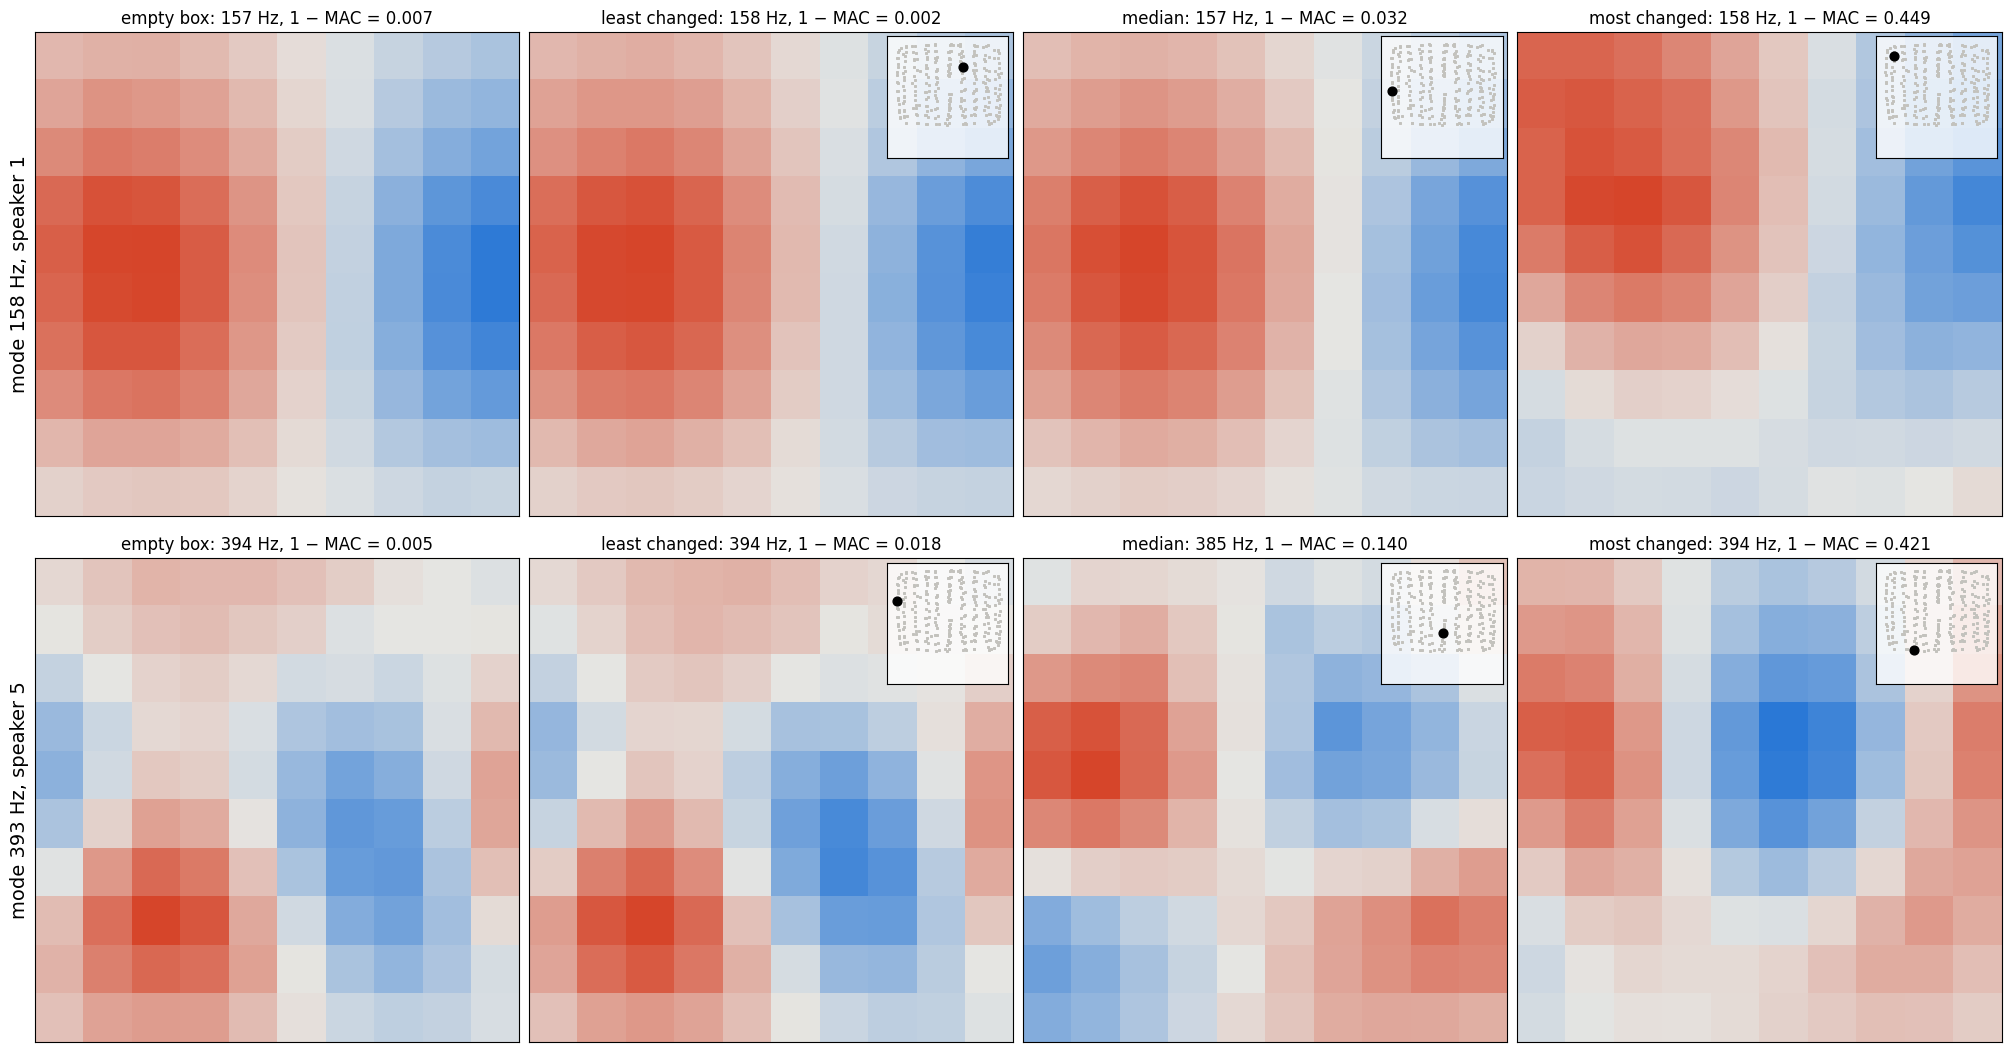

In [12]:
def snap(z):   # viz2 data.norm(ref="avg") + data.mode: rotate so the mean x phase is 0, take the real part, x axis on the grid
    zx = z[0::2]; zx = zx * np.conj(zx.mean()) / abs(zx.mean()); return (zx.real / np.abs(zx.real).max()).reshape(10, 10)
fig, axs = plt.subplots(2, 4, figsize=(20, 10.5), layout="constrained")
for r, (c0, s) in enumerate([(158, 1), (393, 5)]):
    g = t[(np.abs(t["mode"] - c0) < 3) & (t.spk == s)]
    q = g[g.obj == "cube"].sort_values("shape")
    sel = [g[g.obj == "empty"].iloc[0], q.iloc[0], q.iloc[len(q) // 2], q.iloc[-1]]
    for ax, row, name in zip(axs[r], sel, ("empty box", "least changed", "median", "most changed")):
        ax.imshow(snap(x[row.i, np.abs(f - row.fpk).argmin()]), cmap=DIV, vmin=-1, vmax=1)
        ax.set(xticks=[], yticks=[], title=f"{name}: {row.fpk:.0f} Hz, 1 − MAC = {row['shape']:.3f}")
        if row.obj == "cube":
            ins = ax.inset_axes([.74, .74, .25, .25]); ins.set(xticks=[], yticks=[], xlim=(200, 1120), ylim=(1000, 150)); ins.patch.set_alpha(.8)
            ins.scatter(df.col[Cb], df.row[Cb], s=1, c="#c3c2bd"); ins.scatter(row.col, row.row, s=40, c="k")
    axs[r, 0].set_ylabel(f"mode {c0} Hz, speaker {s}", fontsize=14)

**Reading:**
- **Every track rises with distance**, from 0.013-0.11 for close pairs to 0.03-0.31 for far pairs (2-3×), against ~0.02 for empty pairs. Most of the rise happens within the first ~15% of the box; beyond that the curves flatten, so two positions farther apart than that are about equally different.
- **Least:** ~113 Hz (speaker 5) and ~158 Hz (speakers 5/7), ≤ 0.04 even for far pairs. **Most:** ~393 Hz (0.23-0.31), ~242, ~683 and ~193 Hz (speakers 1/7).
- The same mode can differ by speaker: ~158 Hz is 0.03 for speakers 5/7 but 0.08-0.12 for speakers 1/3. The speaker sets which mix of modes forms the peak, and so how sensitive it is.
- **Pictures.** At 158 Hz the least-changed and median positions look like the empty box (one lobe left, opposite phase right); only the most-changed position (far top-left corner, 0.45) drops the lower rows. At 393 Hz the **median** position (0.14) already has rearranged lobes, and the most-changed (0.42) is a different pattern.

**Answer: yes, at every mode.** The mode shape on the lasers differs between positions, more the farther apart they are (2-3× from close to far), always above repeat noise. Relative to its noise, shape is the strongest of the three position signals (shape > level > frequency).

# 7 Where in the Box Does Each Mode Change?

**Question.** For the most common modes: at which cube positions does the level, the frequency or the shape change most? Do the three change in the same places (one effect seen three ways) or in different places (separate effects)?

**Definitions.** The 4 modes found most often across all cube captures. Per cube position, the mean over the speakers that track the mode of:
```
level change = level − mean level(empty)            (dB, same speaker)
freq shift   = f_peak − mean f_peak(empty)          (Hz)
shape change = 1 − MAC(z, v_empty)
field        = Gaussian-weighted average of nearby positions (σ = 45 px), drawn under the dots
noise        = std over the 15 empty captures, ÷ √(speakers)
```
Dots are cube centres of mass on the overhead photo of the empty box; green is the laser patch on the wall (nb96). One colour scale per column.

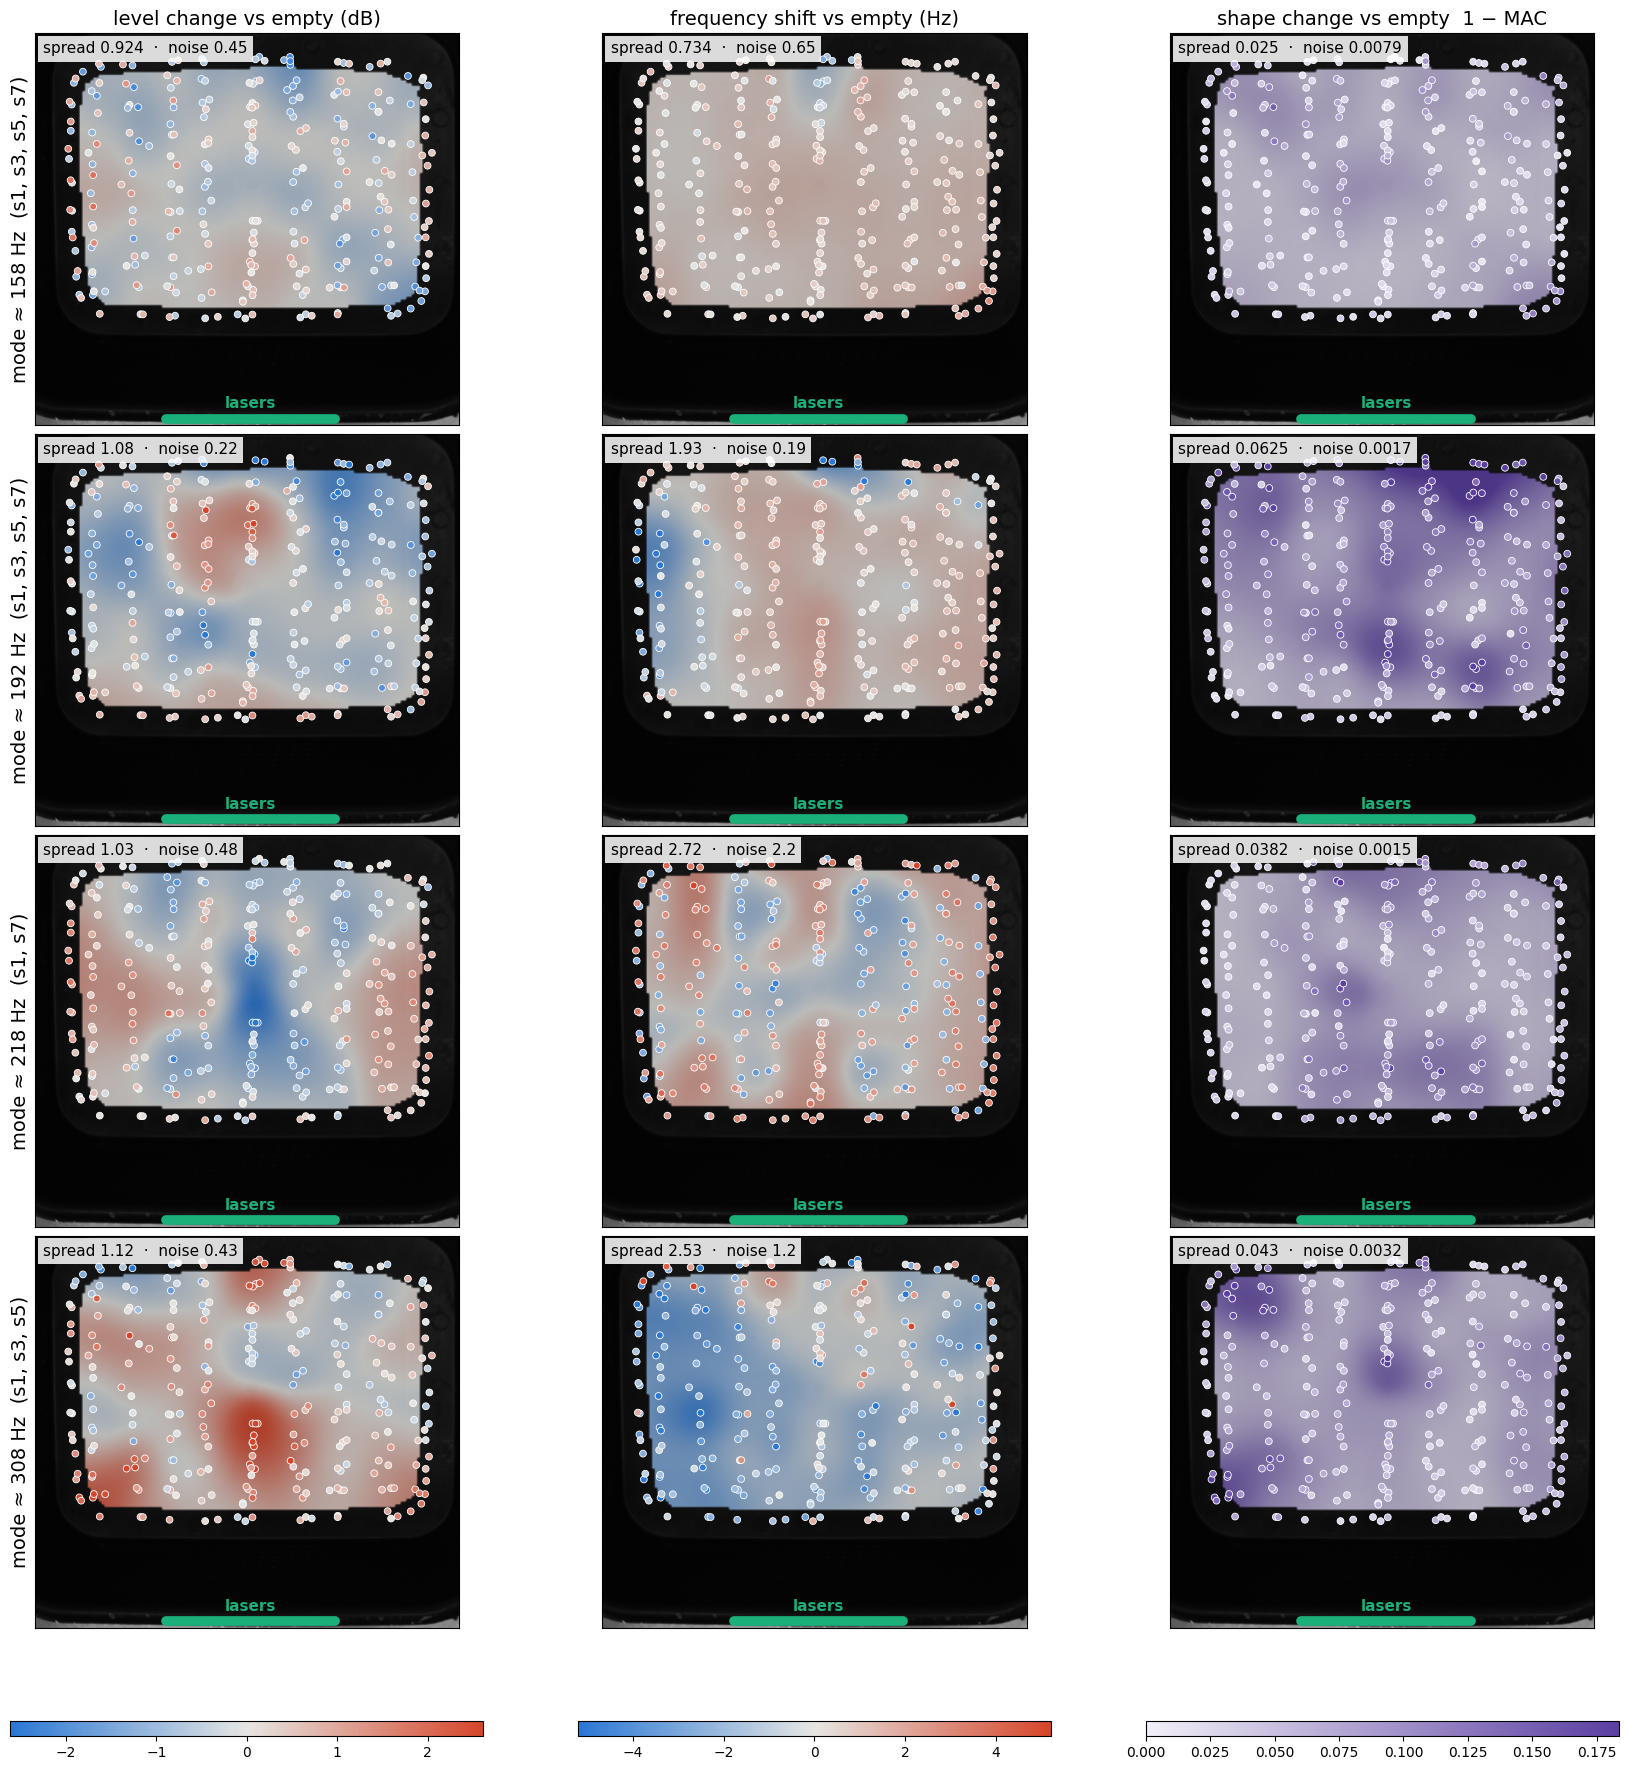

In [13]:
TOP = MODES[np.argsort(occ["cube"].mean(0))[::-1][:4]]
mp = t[t["mode"].isin(TOP)].copy()
mp[["fpk", "level"]] -= mp.groupby(["mode", "spk"])[["fpk", "level"]].transform(lambda v: v[mp.loc[v.index, "obj"] == "empty"].mean())
pos = mp[mp.obj == "cube"].groupby(["mode", "pos"]).agg(row=("row", "first"), col=("col", "first"), level=("level", "mean"), shift=("fpk", "mean"), shape=("shape", "mean")).reset_index()
noise = {c: mp[(mp.obj == "empty") & (mp["mode"] == c)].groupby("spk")[["level", "fpk", "shape"]].std().mean().set_axis(["level", "shift", "shape"]) / np.sqrt(mp[mp["mode"] == c].spk.nunique()) for c in TOP}

img = plt.imread(R / "001464-1/image/02_cropped_overhead.png")[..., :3].mean(2)
gy, gx = np.mgrid[150:1000:6, 200:1120:6]
c0 = df[Cb][["col", "row"]].values
inside = MPath(c0[ConvexHull(c0).vertices]).contains_points(np.c_[gx.ravel(), gy.ravel()], radius=-40).reshape(gx.shape)
def field(q, v):
    W2 = np.exp(-((gx[..., None] - q.col.values) ** 2 + (gy[..., None] - q.row.values) ** 2) / (2 * 45 ** 2))
    return np.where(inside, (W2 * v).sum(-1) / W2.sum(-1), np.nan)
fig, axs = plt.subplots(4, 3, figsize=(17, 17.5), layout="constrained")
for j, (key, label, cmap) in enumerate((("level", "level change vs empty (dB)", DIV), ("shift", "frequency shift vs empty (Hz)", DIV), ("shape", "shape change vs empty  1 − MAC", SEQ))):
    lim = np.nanpercentile(np.abs(pos[key]), 97)
    norm = plt.Normalize(-lim if cmap is DIV else 0, lim)
    for r, c in enumerate(sorted(TOP)):
        ax, q = axs[r, j], pos[pos["mode"] == c]
        ax.imshow(img, cmap="gray", vmin=0, vmax=img.max() * 1.5)
        ax.imshow(field(q, q[key].values), extent=(gx[0, 0], gx[0, -1], gy[-1, 0], gy[0, 0]), cmap=cmap, norm=norm, alpha=.8, interpolation="bilinear")
        ax.scatter(q.col, q.row, c=q[key], cmap=cmap, norm=norm, s=24, edgecolors="white", linewidths=.6)
        ax.plot([.37 * img.shape[1], .65 * img.shape[1]], [985, 985], c="#1baf7a", lw=7, solid_capstyle="round")
        ax.text(.51 * img.shape[1], 962, "lasers", color="#1baf7a", ha="center", fontsize=11, weight="bold")
        ax.text(.02, .98, f"spread {q[key].std():.3g}  ·  noise {noise[c][key]:.2g}", transform=ax.transAxes, va="top", fontsize=11, bbox=dict(fc="white", ec="none", alpha=.85))
        ax.set(xticks=[], yticks=[], xlim=(200, 1120), ylim=(1000, 150))
        if j == 0: ax.set_ylabel(f"mode ≈ {c:.0f} Hz  ({', '.join(f's{s}' for s in sorted(mp[mp['mode'] == c].spk.unique()))})", fontsize=14)
        if r == 0: ax.set_title(label, fontsize=14)
        summary[f"map ~{c:.0f} Hz: {key} spread / noise"] = f"{q[key].std() / noise[c][key]:.1f}"
    fig.colorbar(plt.cm.ScalarMappable(norm, cmap), ax=axs[:, j], orientation="horizontal", shrink=.85, aspect=30)

**Reading:**
- **~158 Hz:** no structure. The level map is salt-and-pepper (spread 0.92 dB, noise 0.45), the frequency map is flat (spread = noise), and the shape change is small (0.025) and the same everywhere.
- **~193 Hz:** structured in all three columns, and **the columns disagree**. The level drops along the top (far) wall and rises in the upper-left middle; the frequency drops along the left wall; the shape changes most in the top-right and bottom-centre-right.
- **~218 Hz:** the level drops in a stripe down the middle; the frequency map is mostly noise (spread 2.7 vs 2.2 Hz).
- **~308 Hz:** louder with the cube in front of the lasers (bottom centre) and in the bottom-left corner; lower in frequency over the left and bottom half, higher at top right; the shape changes most in the left corners.

**Answer: different places.** The strongest mode (~158 Hz) reacts a little and the same everywhere. For the others, level, frequency and shape each have their own map, so they are **separate effects** of position, not one effect seen three ways.

# 8 Q3: Which Modes Change Most, Which Least, and Why?

**Question.** §5-§7 show that some modes barely react to the cube and others react strongly. Which ones, and what property of a mode predicts it?

**Definitions.** Candidate reasons, each measured on the empty box of that speaker:
```
f_e    = empty-box peak frequency (Hz)
level  = empty-box P at the peak (dB): how strongly the speaker drives it
η      = −3 dB width / f_e of the empty peak: damping (nb99 §5.3); wide = damped, or several modes merged
gap    = distance to the nearest other peak in the empty spectrum (prominence ≥ 1 dB), Hz: how crowded
MPC    = |Σ z²|² / (Σ|z|²)², mean over empty captures: 1 = a real (standing) mode, every laser in or out of phase; low = complex
```
Sensitivity: `shape far` (§6), `freq / noise` and `level / noise` (§5). Spearman ρ over tracks below 800 Hz.

,shape far,freq / noise,level / noise
Spearman ρ,,,
f_e,0.62,0.31,0.39
level_e,-0.43,-0.37,-0.14
eta,-0.55,-0.17,-0.31
gap,0.51,0.27,0.31
MPC,-0.39,-0.41,-0.38


f_e    level_e    eta      gap    MPC  shape far  freq / noise  \
mode  spk                                                                       
112.5 5    116.769   2.610000  0.059   21.538  0.979      0.029         4.058   
157.5 7    155.077  21.857000  0.047   17.692  0.994      0.034         0.798   
      5    155.744  16.794001  0.075   17.692  0.873      0.036         0.969   
      3    157.385  16.049999  0.089   17.692  0.713      0.078         0.695   
217.5 1    214.513  21.846001  0.060   20.769  0.715      0.081         1.007   
192.5 3    196.838  17.083000  0.082   16.923  0.579      0.091         6.172   
307.5 3    306.615  10.776000  0.078   43.077  0.587      0.097         1.326   
      5    311.744  12.834000  0.089   48.462  0.512      0.100         1.329   
192.5 5    197.929  13.201000  0.056   14.615  0.527      0.105         4.035   
217.5 7    215.846  16.382999  0.000    3.077  0.795      0.107         0.972   
557.5 3    554.872  -5.879000  0.044   46.923  0.697      0.112         1.124   
307.5 1    305.577  11.033000  0.034   14.615  0.485      0.114         3.408   
157.5 1    157.846  19.656000  0.046   17.692  0.442      0.116         0.823   
557.5 5    550.604  -4.929000  0.038  107.692  0.727      0.122         2.398   
452.5 7    450.000   3.071000  0.031   53.077  0.640      0.155         4.161   
192.5 1    193.077  21.764000  0.044   20.769  0.446      0.158         4.175   
      7    194.692  16.844999  0.039   26.923  0.635      0.173         1.186   
682.5 7    683.744 -10.285000  0.057  116.154  0.121      0.193         2.022   
242.5 5    240.350  10.408000  0.030   23.077  0.870      0.209         1.837   
392.5 7    396.923   2.420000  0.035   53.077  0.253      0.235         6.110   
      5    393.897   4.530000  0.054   48.462  0.680      0.247         3.577   
      3    392.051   3.540000  0.047   36.923  0.780      0.310         1.240   

           level / noise  
mode  spk                 
112.5 5            1.163  
157.5 7            1.404  
      5            1.078  
      3            1.135  
217.5 1            1.564  
192.5 3            2.698  
307.5 3            1.236  
      5            2.220  
192.5 5            2.095  
217.5 7            1.774  
557.5 3            1.937  
307.5 1            1.767  
157.5 1            1.792  
557.5 5            2.862  
452.5 7            1.374  
192.5 1            3.128  
      7            2.099  
682.5 7            1.865  
242.5 5            2.923  
392.5 7            2.963  
      5            5.279  
      3            2.042

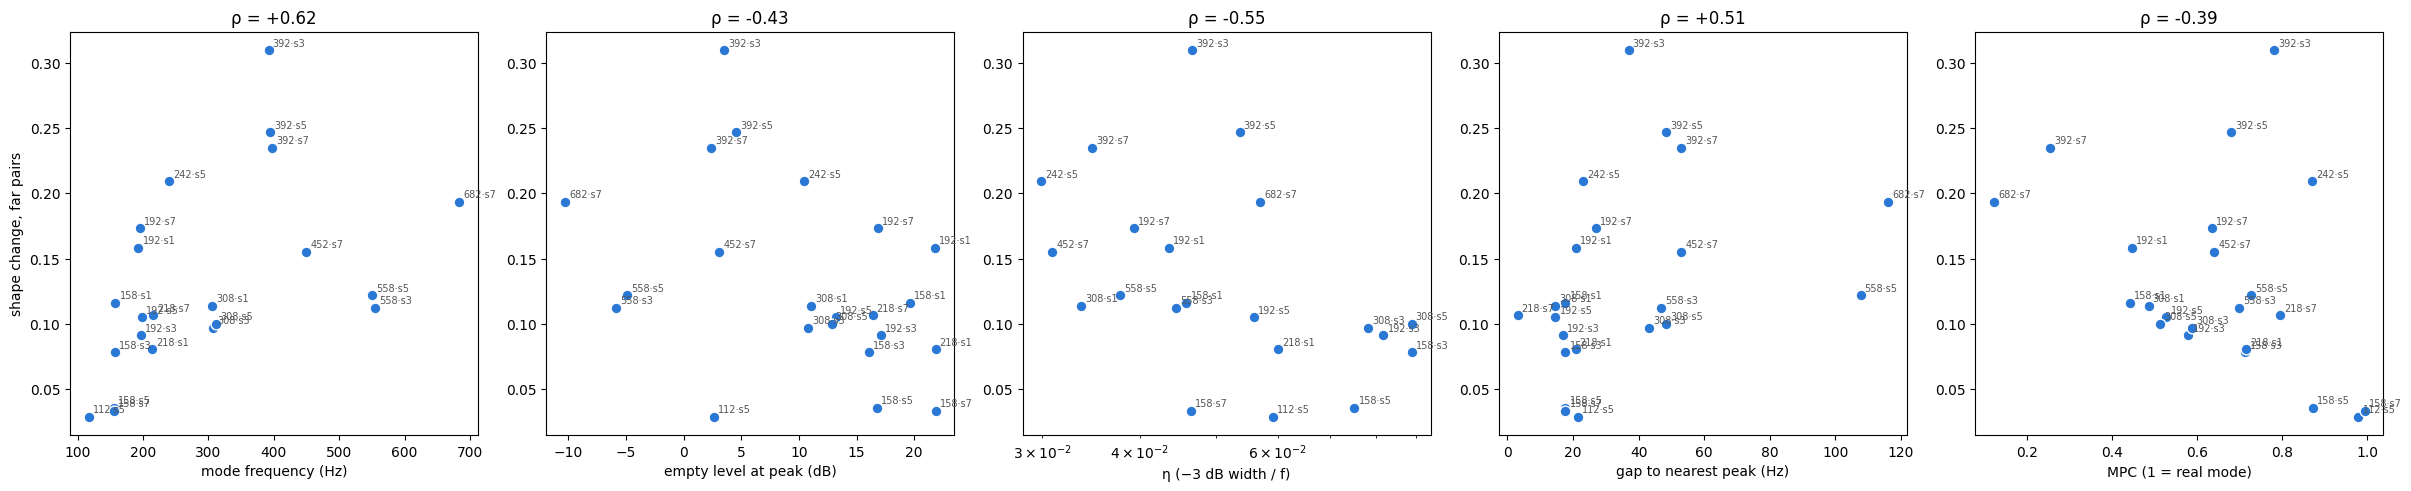

In [14]:
K = T.join(PR[["shape close", "shape far"]]).join(Z[["freq / noise", "level / noise"]])
K["MPC"] = t[t.obj == "empty"].groupby(["mode", "spk"]).mpc.mean()
K = K[K.f_e < 800]
props = [("f_e", "mode frequency (Hz)"), ("level_e", "empty level at peak (dB)"), ("eta", "η (−3 dB width / f)"), ("gap", "gap to nearest peak (Hz)"), ("MPC", "MPC (1 = real mode)")]
fig, axs = plt.subplots(1, 5, figsize=(24, 4.8), layout="constrained")
for ax, (xk, xl) in zip(axs, props):
    ax.scatter(K[xk], K["shape far"], s=60, c="#2a78d6", edgecolors="white")
    for (c, s), v in K.iterrows(): ax.annotate(f"{c:.0f}·s{s}", (v[xk], v["shape far"]), fontsize=7, xytext=(3, 3), textcoords="offset points", color="#555")
    ax.set(xlabel=xl, ylabel="shape change, far pairs" if xk == "f_e" else "", title=f"ρ = {spearmanr(K[xk], K['shape far'])[0]:+.2f}", xscale="log" if xk == "eta" else "linear")
rho = pd.DataFrame({yk: {xk: spearmanr(K[xk], K[yk])[0] for xk, _ in props} for yk in ("shape far", "freq / noise", "level / noise")}).round(2)
for xk, _ in props: summary[f"ρ(shape far, {xk})"] = f"{rho.loc[xk, 'shape far']:+.2f}"
display(rho.rename_axis("Spearman ρ"))
K.sort_values("shape far")[["f_e", "level_e", "eta", "gap", "MPC", "shape far", "freq / noise", "level / noise"]].round(3)

**Reading** (ranking table from least to most position-sensitive shape):
- **Least:** ~113 Hz and ~158 Hz (speakers 3/5/7, 0.03-0.08), the lowest modes. **Most:** ~393 Hz (all three speakers, 0.24-0.31), ~242 Hz, ~683 Hz and ~193 Hz for speakers 1/7 (0.16-0.21). ~558 Hz is in the middle (0.11-0.12).
- **Shape sensitivity follows frequency most** (ρ = +0.62). It is also higher for weaker modes (ρ = −0.43) and complex ones (low MPC, ρ = −0.39).
- **Crowding is not the reason: isolated peaks change *more*** (ρ = +0.51 with the gap). The damping correlation (ρ = −0.55, more damped → *less* change) is probably frequency again: η falls with frequency in this set.
- **Frequency sensitivity is only weakly predictable** (|ρ| ≤ 0.41): a bit more for complex and weaker modes.

**Why (a hypothesis that fits these numbers):** the cube adds mass where it sits. To first order it lowers each underlying mode's frequency by `Δf / f ≈ −½ · m · φ(pos)² / M_modal`, where `φ(pos)` is how much that mode moves the floor under the cube. A **low-order mode** (~158 Hz) moves the whole floor together, so `φ` changes slowly across the floor and *where* the cube sits barely matters. **Higher modes** have nodal lines across the floor, so a few cm takes the cube from a node (no effect) to an antinode (largest effect). Each underlying mode shifts by a position-dependent amount, and in this damped box a peak is a blend of modes, so the blend changes: shape, level and peak position all move. This also explains why the shape difference saturates within ~15% of the box (§6, about one lobe of a high mode) and why the bands between resonances change most (§3). The rise of ~558 Hz is the one thing mass alone cannot explain.

**Answer:** low modes (~113, ~158 Hz) change least, ~393, ~242 and ~683 Hz most. The best predictor is mode frequency (ρ = +0.62), consistent with mass loading on modes with more nodal lines; crowding is refuted.

# 9 Which Lasers See the Position?

**Question.** Which lasers' signals change most when the cube moves, and which least? Do some rows, columns or sides of the grid see more?

**Definitions.** Per laser `l` and axis `c` (the same position test as nb99 §4, per laser instead of pooled). This one looks along frequency: it compares each laser's own spectrum between captures.
```
y(l,j,c)       = mean_{f ∈ band j} 20 log10 |X(l,f,c)|, 78 bands of 7.7 Hz, 100-700 Hz      # dB
D_l(a, b)      = sqrt( mean_j (y_a(l,j,c) − y_b(l,j,c))² )                                 # how different laser l's spectrum is between captures a, b
move_l         = mean D_l(far cube pairs, D_pos > 0.4) − mean D_l(close cube pairs, D_pos < 0.05)
noise_l        = mean D_l(back-to-back empty pairs)
move / noise_l = position signal of that one laser, in units of its own repeat noise
```
Same speaker only; maps are the mean over the 4 speakers. Laser `l = 10 · row + col` in the PCLK grid order (row 0 on top). How this grid maps onto the wall (mirroring) is not verified (nb102), so read rows and columns as grid order, not box sides.

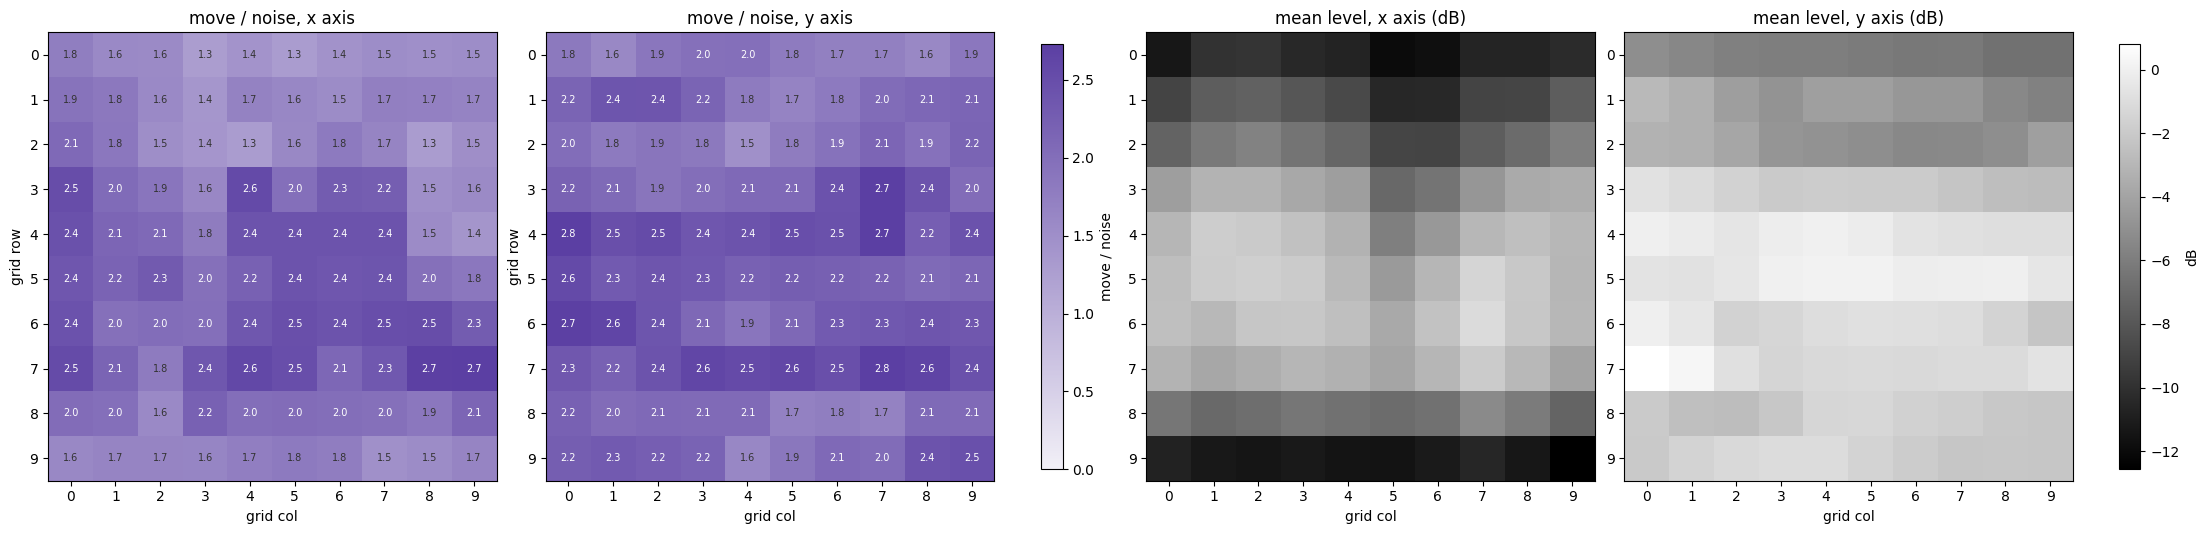

In [15]:
Y = (20 * np.log10(np.abs(X[:, :780]).transpose(0, 2, 1) + 1e-12)).reshape(len(df), 200, 78, 10).mean(-1)   # (captures, 200 = laser·2 + axis, 78 bands)
MN, LV = [], []
for s in SPK:
    c, e = df.index[Cb & (df.spk == s)], df[E & (df.spk == s)]
    g = df.loc[c]; i, j = np.triu_indices(len(c), 1)
    D = np.hypot(g.row.values[i] - g.row.values[j], g.col.values[i] - g.col.values[j]) / 1151
    y = Y[c].transpose(1, 0, 2)                                                    # (200, n, 78)
    sq = (y ** 2).sum(-1); Dl = np.sqrt(np.maximum(sq[:, :, None] + sq[:, None, :] - 2 * y @ y.transpose(0, 2, 1), 0) / 78)[:, i, j]   # (200, pairs)
    ep = [(a, b) for _, q in e.groupby("layout") for a, b in zip(q.index[:-1], q.index[1:])]
    nz = np.mean([np.sqrt(((Y[a] - Y[b]) ** 2).mean(-1)) for a, b in ep], 0)      # (200,)
    MN.append((Dl[:, D > .4].mean(1) - Dl[:, D < .05].mean(1)) / nz)
    LV.append(Y[c].mean((0, 2)))
MN, LV = np.array(MN).reshape(4, 100, 2), np.array(LV).reshape(4, 100, 2)       # (speakers, lasers, axis)
m = MN.mean(0)                                                                     # (100, 2)

fig, axs = plt.subplots(1, 4, figsize=(22, 5.5), layout="constrained")
for k, ax in enumerate(axs[:2]):
    im = ax.imshow(m[:, k].reshape(10, 10), cmap=SEQ, vmin=0, vmax=np.percentile(m, 99))
    for (r, cc), v in np.ndenumerate(m[:, k].reshape(10, 10)): ax.text(cc, r, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if v > .7 * m.max() else "#333")
    ax.set(title=f"move / noise, {'xy'[k]} axis", xticks=range(10), yticks=range(10), xlabel="grid col", ylabel="grid row")
fig.colorbar(im, ax=axs[:2], shrink=.8, label="move / noise")
for k, ax in enumerate(axs[2:]):
    im2 = ax.imshow(LV.mean(0)[:, k].reshape(10, 10), cmap="gray", vmin=LV.mean(0).min(), vmax=LV.mean(0).max())
    ax.set(title=f"mean level, {'xy'[k]} axis (dB)", xticks=range(10), yticks=range(10), xlabel="grid col")
fig.colorbar(im2, ax=axs[2:], shrink=.8, label="dB")
G = m.reshape(10, 10, 2)
summary["laser move / noise, over lasers × axes"] = pm(m)
summary["laser move / noise, grid rows 3-7"], summary["laser move / noise, grid rows 0-2 and 8-9"] = pm(G[3:8]), pm(np.r_[G[:3], G[8:]])
summary["laser move / noise, x / y axis"] = f"{m[:, 0].mean():.2f} / {m[:, 1].mean():.2f}"
summary["ρ(laser move / noise, laser level)"] = f"{spearmanr(LV.mean(0).ravel(), m.ravel())[0]:+.2f}"

,most,least
0,"laser 77 y (row 7, col 7): 2.76","laser 3 x (row 0, col 3): 1.27"
1,"laser 40 y (row 4, col 0): 2.76","laser 28 x (row 2, col 8): 1.29"
2,"laser 37 y (row 3, col 7): 2.73","laser 5 x (row 0, col 5): 1.29"
3,"laser 47 y (row 4, col 7): 2.72","laser 24 x (row 2, col 4): 1.30"
4,"laser 79 x (row 7, col 9): 2.72","laser 13 x (row 1, col 3): 1.39"


,speaker 1,speaker 3,speaker 5,speaker 7
mean,2.47,1.87,2.30,1.55
max,3.86,3.03,3.72,2.61
best laser,"laser 47 x (row 4, col 7)","laser 78 y (row 7, col 8)","laser 99 y (row 9, col 9)","laser 79 x (row 7, col 9)"


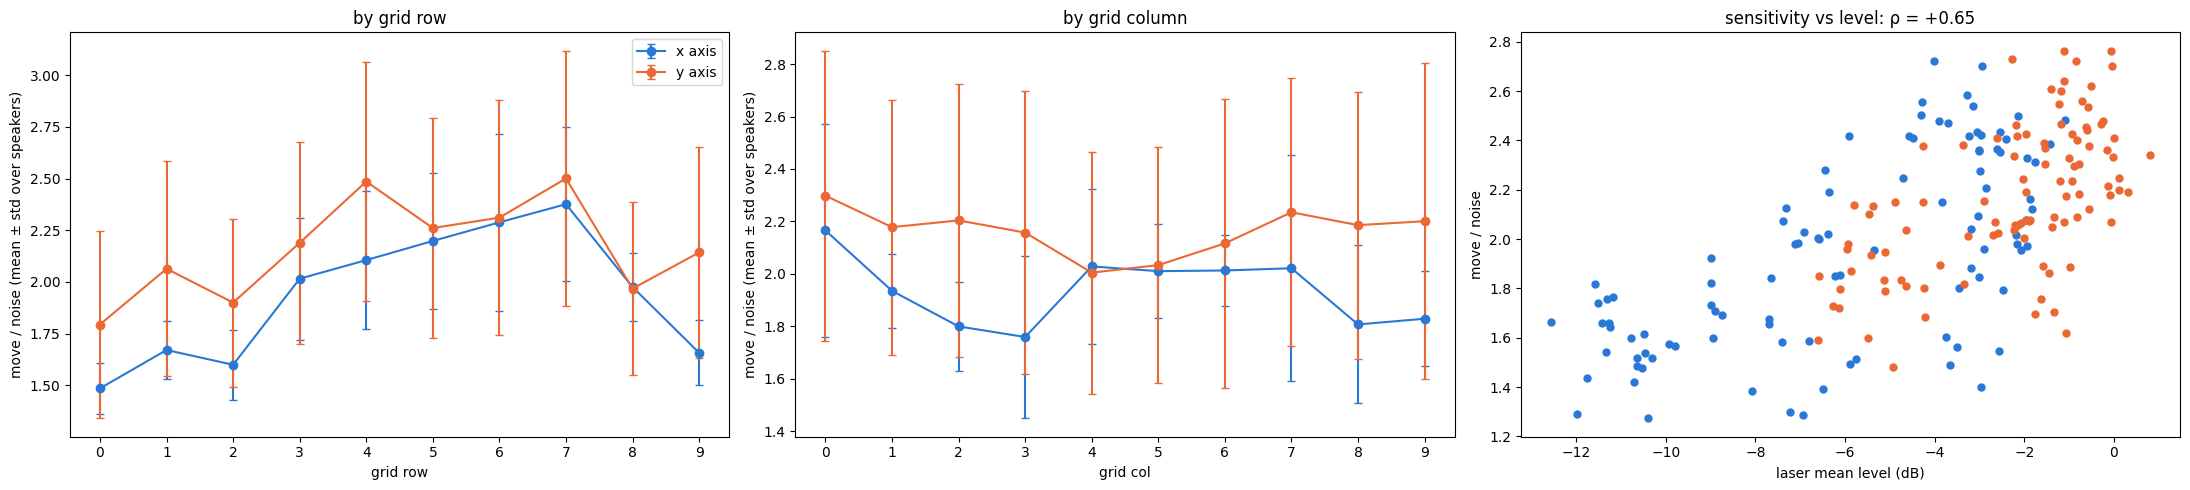

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(22, 5))
for k, c in enumerate(("#2a78d6", "#eb6834")):
    G = MN[:, :, k].reshape(4, 10, 10)
    for ax, ax_mean, lab in ((axs[0], 2, "grid row"), (axs[1], 1, "grid col")):
        v = G.mean(ax_mean); ax.errorbar(range(10), v.mean(0), v.std(0), fmt="o-", c=c, capsize=3, label=f"{'xy'[k]} axis")
        ax.set(xlabel=lab, ylabel="move / noise (mean ± std over speakers)", xticks=range(10))
    axs[2].scatter(LV.mean(0)[:, k], m[:, k], s=25, c=c, label=f"{'xy'[k]} axis")
axs[0].set_title("by grid row"); axs[1].set_title("by grid column"); axs[0].legend()
axs[2].set(xlabel="laser mean level (dB)", ylabel="move / noise", title=f"sensitivity vs level: ρ = {spearmanr(LV.mean(0).ravel(), m.ravel())[0]:+.2f}")
plt.tight_layout()
name = lambda i: f"laser {i // 2} {'xy'[i % 2]} (row {i // 20}, col {i // 2 % 10})"
o = np.argsort(m.ravel())
display(pd.DataFrame({"most": [f"{name(i)}: {m.ravel()[i]:.2f}" for i in o[::-1][:5]], "least": [f"{name(i)}: {m.ravel()[i]:.2f}" for i in o[:5]]}))
pd.DataFrame({f"speaker {s}": {"mean": f"{MN[n].mean():.2f}", "max": f"{MN[n].max():.2f}", "best laser": name(MN[n].ravel().argmax())} for n, s in enumerate(SPK)})

**Reading:**
- **Every laser sees the position**, at 1.3-2.8× its own repeat noise.
- **Rows matter, columns barely do.** The row profile rises from ~1.5 (row 0) to ~2.4 (rows 4-7) and falls again at rows 8-9; the column profile is flat within the spread over speakers. The y axis is slightly more sensitive than x. Most: 77 y, 40 y, 37 y, 47 y, 79 x (2.7-2.8×). Least: rows 0-2 and row 9 on the x axis (1.3-1.6×).
- **It follows how much the laser's spot moves** (ρ = +0.65 with the laser's mean level). The quietest lasers (rows 0 and 9 on x, −12 dB) see the least.
- **The best laser depends on the speaker.** Speakers 1 and 5 average 2.3-2.5× (best laser 3.7-3.9×), speakers 3 and 7 1.6-1.9× (best 2.6-3.0×), and the best laser is a different one for each speaker (47 x, 78 y, 99 y, 79 x). §2 again: each speaker drives a different mix of modes, so different lasers move most.

**Answer: the loud ones.** No laser is blind; the middle grid rows see the position most and the quiet top and bottom rows least, in proportion to each laser's signal. There is no special side beyond that, and which lasers are best changes with the speaker.

# 10 Does Phase Normalization Change the Answers?

**Question.** viz2 normalizes phase to a reference laser (or the average laser) before showing a mode. Should the comparisons above have done the same, and would the answers change?

**Definitions.**
```
z'_l          = z_l · conj(z_ref) / |z_ref|, per bin       # viz2 data.norm; ref = a laser, or the complex mean over lasers ("avg")
snapshot      = Re(z')                                     # viz2 data.mode: the wall at the instant the reference is at phase 0
real-snapshot MAC = (a·b)² / (|a|² |b|²), a = Re(z'_a), b = Re(z'_b)
MPC           = |Σ z²|² / (Σ|z|²)²                        # 1 = real mode: the snapshot loses nothing
```
**Complex MAC cannot change:** the rotation multiplies the whole 200-vector by one unit complex number, and `|x_a · x_b*|²` cancels it. Every number in §2-§8 uses complex MAC (or magnitudes), so none depend on a reference. Only the real snapshot can. Test: speaker 1, 100-700 Hz, 4000 random cube pairs plus back-to-back empty pairs, three references.

In [17]:
def rot(z, ref):
    r = {"laser 0 x": z[..., 0], "laser 55 x": z[..., 110], "avg x": z[..., 0::2].mean(-1)}[ref]
    return z * (r.conj() / (np.abs(r) + 1e-12))[..., None]
def rmac(a, b): return (a * b).sum(-1) ** 2 / ((a * a).sum(-1) * (b * b).sum(-1))
g = df[Cb & (df.spk == 1)]
i, j = np.triu_indices(len(g), 1)
s = np.random.default_rng(0).choice(len(i), 4000, replace=False); i, j = i[s], j[s]
D = np.hypot(g.row.values[i] - g.row.values[j], g.col.values[i] - g.col.values[j]) / 1151
xa, xb = x[g.index[i], :780], x[g.index[j], :780]
ea = df[E & (df.spk == 1)].groupby("layout").apply(lambda q: list(zip(q.index[:-1], q.index[1:])), include_groups=False).sum()
out = {"complex MAC": mac(xa, xb), "complex MAC, rotated (laser 55 x)": mac(rot(xa, "laser 55 x"), rot(xb, "laser 55 x"))}
emp = {"complex MAC": np.mean([mac(x[a, :780], x[b, :780]).mean() for a, b in ea])}
emp["complex MAC, rotated (laser 55 x)"] = emp["complex MAC"]
for ref in ("laser 0 x", "laser 55 x", "avg x"):
    out[f"real snapshot, ref {ref}"] = rmac(rot(xa, ref).real, rot(xb, ref).real)
    emp[f"real snapshot, ref {ref}"] = np.mean([rmac(rot(x[a, :780], ref).real, rot(x[b, :780], ref).real).mean() for a, b in ea])
PH = pd.DataFrame({k: {"empty repeats": emp[k], "cube, close (D_pos < 0.05)": v[D < .05].mean(), "cube, far (D_pos > 0.4)": v[D > .4].mean()} for k, v in out.items()}).T
for k, r in PH.iterrows(): summary[f"{k}: empty / close / far"] = " / ".join(f"{v:.3f}" for v in r)
PH.round(3)

,empty repeats,"cube, close (D_pos < 0.05)","cube, far (D_pos > 0.4)"
complex MAC,0.994,0.901,0.744
"complex MAC, rotated (laser 55 x)",0.994,0.901,0.744
"real snapshot, ref laser 0 x",0.962,0.717,0.499
"real snapshot, ref laser 55 x",0.984,0.788,0.571
"real snapshot, ref avg x",0.983,0.827,0.629


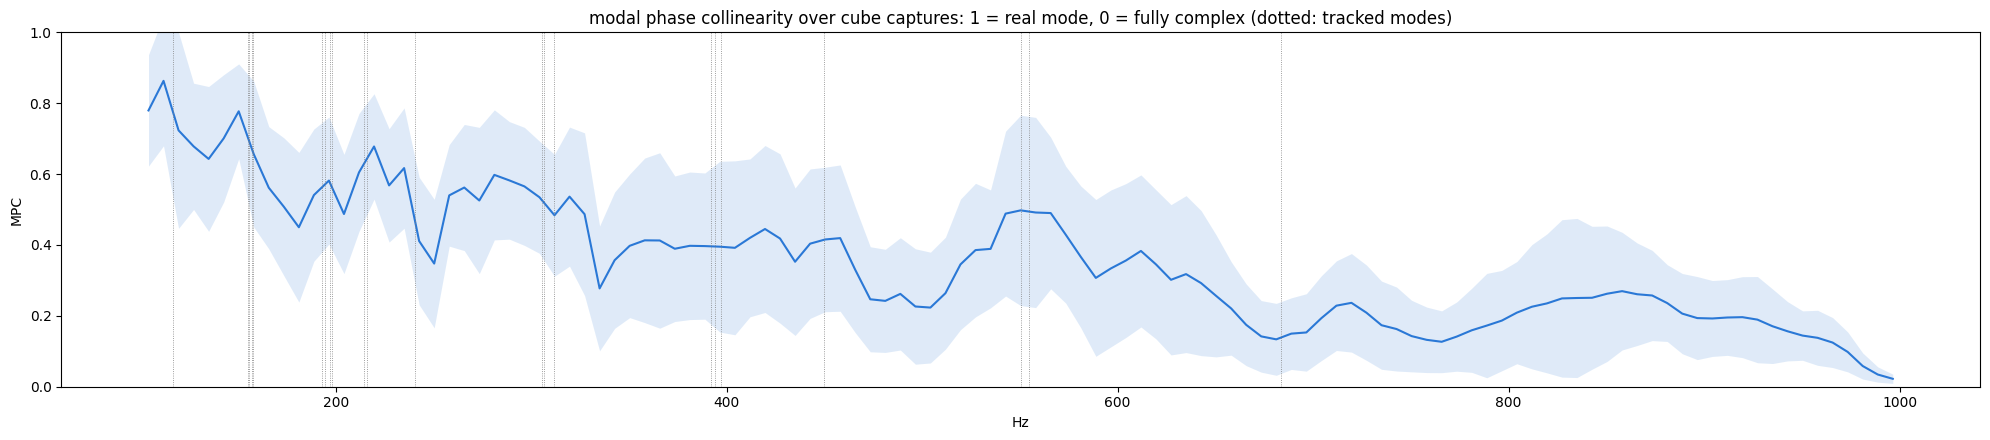

In [18]:
M = np.abs((x * x).sum(-1)) ** 2
fig, ax = plt.subplots(figsize=(20, 4.5))
mm, sd = band(M[Cb]).mean(0), band(M[Cb]).std(0)
ax.fill_between(fb, mm - sd, mm + sd, color="#2a78d6", alpha=.15, lw=0); ax.plot(fb, mm, c="#2a78d6")
for c in K.f_e: ax.axvline(c, c="gray", lw=.6, ls=":")
ax.set(xlabel="Hz", ylabel="MPC", ylim=(0, 1), title="modal phase collinearity over cube captures: 1 = real mode, 0 = fully complex (dotted: tracked modes)")
plt.tight_layout()
summary["MPC, 100-160 Hz"], summary["MPC, 600-1000 Hz"] = pm(M[Cb][:, f < 160].mean(1)), pm(M[Cb][:, f > 600].mean(1))

**Reading:**
- Complex MAC is identical before and after rotation (0.994 / 0.901 / 0.744), as it must be.
- The real snapshot gives **lower MAC everywhere**: empty repeats 0.96-0.98, close pairs 0.72-0.83, far pairs 0.50-0.63. It **depends on the reference**: `avg` keeps the most, laser 0 (a corner, weak motion, noisy phase) the least.
- The close-far gap is even larger with the snapshot (0.20-0.22 vs 0.16 complex), and both stay well below the empty repeats, with every reference.
- The motion is **far from real**: MPC ~0.75 below 160 Hz, 0.4-0.6 up to 330 Hz, ~0.4 at 350-450 Hz, 0.15-0.3 above 600 Hz. One snapshot of a complex mode is not the whole mode.

**Answer: no.** Phase normalization cannot change complex MAC, so no answer above changes. It only matters for the real snapshot, which loses information because these modes are complex. Use complex MAC to compare modes, and the snapshot (viz2, `ref = avg`) to look at them.

# 11 Conclusion

Every key number in the notebook, grouped by section (mean ± std over the unit of each section: speakers, tracks, lasers or pairs).

In [19]:
RESULTS = {
    "2 speakers": ["MAC repeat, 100-700 Hz", "MAC speakers, 100-700 Hz", "MAC speakers, 180-320 Hz", "MAC floor, 100-700 Hz", "capture own, k=8", "capture other, k=8", "capture own, k=32", "capture other, k=32"],
    "3 position vs drift": ["pair MAC, repeat ceiling", "pair MAC, close (D_pos < 0.05)", "pair MAC, far (D_pos > 0.4)", "fit: MAC per box length moved", "fit: MAC per hour"],
    "4 empty vs cube": ["capture by empty V, empty held-out, k=8", "capture by empty V, cube, k=8", "capture by empty V, empty held-out, k=32", "capture by empty V, cube, k=32", "modes in ≥ 90% of every speaker's captures", "tracks (mode, speaker)"],
    "5 Q1 freq & level": [k for k in summary if k.endswith(", over tracks") or k.startswith("|Δ")],
    "6 Q2 shape": [k for k in summary if k.startswith(("1 − MAC", "shape vs empty"))],
    "7 maps": [k for k in summary if k.startswith("map ")],
    "8 Q3 why": [k for k in summary if k.startswith("ρ(shape")],
    "9 lasers": [k for k in summary if "laser" in k and k.startswith(("laser", "ρ(laser"))],
    "10 phase": [k for k in summary if k.startswith(("complex MAC", "real snapshot", "MPC"))],
}
pd.concat({h: show(*k) for h, k in RESULTS.items()}, names=["section", "metric"])

value
section             metric                                                                   
2 speakers          MAC repeat, 100-700 Hz                                        0.98 ± 0.01
                    MAC speakers, 100-700 Hz                                      0.49 ± 0.07
                    MAC speakers, 180-320 Hz                                      0.85 ± 0.04
                    MAC floor, 100-700 Hz                                                0.11
                    capture own, k=8                                            0.839 ± 0.023
                    capture other, k=8                                          0.684 ± 0.024
                    capture own, k=32                                           0.944 ± 0.023
                    capture other, k=32                                         0.932 ± 0.022
3 position vs drift pair MAC, repeat ceiling                                            0.984
                    pair MAC, close (D_pos < 0.05)                              0.878 ± 0.018
                    pair MAC, far (D_pos > 0.4)                                 0.721 ± 0.017
                    fit: MAC per box length moved                                      -0.181
                    fit: MAC per hour                                                 -0.0018
4 empty vs cube     capture by empty V, empty held-out, k=8                     0.839 ± 0.023
                    capture by empty V, cube, k=8                               0.792 ± 0.024
                    capture by empty V, empty held-out, k=32                    0.944 ± 0.023
                    capture by empty V, cube, k=32                              0.939 ± 0.022
                    modes in ≥ 90% of every speaker's captures                         158 Hz
                    tracks (mode, speaker)                                                 24
5 Q1 freq & level   freq std cube (Hz), over tracks                               2.28 ± 1.28
                    freq std / f0 (%), over tracks                                0.79 ± 0.47
                    freq / noise, over tracks                                     2.32 ± 1.66
                    level std cube (dB), over tracks                              1.18 ± 0.20
                    level / noise, over tracks                                    2.03 ± 0.93
                    |Δfreq| / noise, close pairs (D_pos < 0.05)                   1.77 ± 1.07
                    |Δfreq| / noise, far pairs (D_pos > 0.45)                     2.59 ± 2.04
                    |Δlevel| / noise, close pairs (D_pos < 0.05)                  1.41 ± 0.63
                    |Δlevel| / noise, far pairs (D_pos > 0.45)                    1.97 ± 0.92
6 Q2 shape          1 − MAC, noise pairs, over tracks < 800 Hz                  0.021 ± 0.016
                    1 − MAC, close pairs, over tracks < 800 Hz                  0.050 ± 0.022
                    1 − MAC, far pairs, over tracks < 800 Hz                    0.132 ± 0.070
                    shape vs empty: cube, over tracks < 800 Hz                  0.085 ± 0.041
                    shape vs empty: empty repeats, over tracks < 80...          0.010 ± 0.008
7 maps              map ~158 Hz: level spread / noise                                     2.0
                    map ~192 Hz: level spread / noise                                     4.8
                    map ~218 Hz: level spread / noise                                     2.1
                    map ~308 Hz: level spread / noise                                     2.6
                    map ~158 Hz: shift spread / noise                                     1.1
                    map ~192 Hz: shift spread / noise                                    10.3
                    map ~218 Hz: shift spread / noise                                     1.2
                    map ~308 Hz: shift spread / noise                                     2.1
                    map ~158 Hz: shape spread 

## Answers

| § | Question | Key number | Answer |
|---|---|---|---|
| 2 | do speakers see the same modes? | capture own / other: k = 8 0.84 / 0.68, k = 32 0.94 / 0.93 | **same patterns, different mix**: compare within a speaker |
| 3 | does the wall's shape change with position, or drift? | pair MAC 0.88 close → 0.72 far (ceiling 0.98); −0.18 per box, ≈ 0 per hour | **yes, position**, not drift |
| 4 | new modes, or reweighted? | capture by empty patterns, cube vs empty: k = 8 0.79 vs 0.84, k = 32 equal | **reweighted**: no new patterns, some peaks appear / fade |
| 5 | Q1: frequency and amplitude vs position | f std 0.5-4.8 Hz (≤ 1.5%); \|Δf\| 1.75 → 2.6× noise; level 1-5× noise | **both change**; frequency a little, for ~⅓ of modes; amplitude for all |
| 6 | Q2: mode shape at the same mode | 1 − MAC 0.013-0.11 close → 0.03-0.31 far (noise ~0.02) | **yes, every mode**, saturating after ~15% of the box |
| 7 | where in the box? | ~158 Hz flat; ~193 Hz three different maps | level, frequency and shape are **separate effects** |
| 8 | Q3: which modes, why? | ρ(shape far, f) = +0.62, ρ(gap) = +0.51 | low modes least, ~393 / ~242 / ~683 Hz most; **mass loading on nodal lines**, not crowding |
| 9 | which lasers? | 1.3-2.8× noise; ρ with laser level +0.65 | **the loud ones** (middle grid rows); best laser depends on speaker |
| 10 | does phase normalization matter? | complex MAC identical; snapshot 0.96 / 0.78 / 0.57 (avg) | **no** for MAC; snapshot only for viewing (MPC 0.2-0.75) |

**Do different positions have different modes?** Not different *modes*: the cube creates no new spatial patterns (§4). But **every mode is different at every position**, in three separate ways: its **shape** on the wall changes most (§6), its **amplitude** changes for every mode (§5), and its **frequency** moves a little for about a third of the modes (§5). All three grow with the distance the cube moved and saturate after ~15% of the box. The low ~113 / ~158 Hz modes barely react; higher modes react most, consistent with mass loading on modes with more nodal lines across the floor (§8).

## Open Questions

- **~558 Hz rises** by 4.5-8 Hz with the cube. Mass loading only lowers frequencies: stiffening by the cube's contact, or a different peak taking over?
- **Empty and cube captures were recorded at different times.** §3 shows no drift within the cube session, but the empty-vs-cube comparisons (§4, §5 shifts, §6 vs empty) could include a session offset.
- **Laser grid orientation** on the wall is not verified (nb102), so §9 rows / columns are grid order, not box sides.
- **Some empty peaks never move** (std 0, floored at 0.4 Hz), so the largest `freq / noise` ratios are rough.
- **One box.** Does the frequency ranking (§8) hold in gastro (sharp modes) and cardboard (few patterns)?

## What to Try

1. **Record empty captures interleaved with the cube grid** (e.g. every 20 positions), to separate session offset from the cube's effect.
2. **Features:** shape at the peaks (complex, within one speaker) carries the most position information per unit noise; peak frequency carries little except for a few modes. Weight the 300-700 Hz band and the louder lasers.
3. **Repeat §5-§8 in gastro and cardboard** to test the mass-loading explanation: in a box with sharp, isolated modes, low modes should still react least.